In [51]:
from __future__ import annotations

import pickle
import numpy as np
from nltk.chunk.named_entity import shape
from scipy.interpolate import CubicSpline
import math
import torch


In [52]:
import umap, sys
print("File:", umap.__file__)
print("Version:", getattr(umap, "__version__", "no __version__"))


File: C:\Users\alysw\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\__init__.py
Version: 0.5.9.post2


In [53]:
#Check to see if all files have been processed
with open("interpolated_data_alt.pkl", "rb") as f:
    data = pickle.load(f)

print("Number of files in pickle:", len(data.keys()))
print("File names:", list(data.keys()))


Number of files in pickle: 24
File names: ['TrackData_2021-06-07_untagged 1.xlsx', 'TrackData_2021-06-09_Yellow 8.xlsx', 'TrackData_2021-08-24_Brown (Rq).xlsx', 'TrackData_2021-08-25_Red 70.xlsx', 'TrackData_2021-08-26_White (R73).xlsx', 'TrackData_2021-08-27_Yellow 21.xlsx', 'TrackData_2021-09-01_Untagged 3.xlsx', 'TrackData_2021-09-02_Blue 83.xlsx', 'TrackData_2021-09-03_White 51.xlsx', 'TrackData_2021-09-15_Green 40.xlsx', 'TrackData_2021-09-16_Red 25.xlsx', 'TrackData_2021-09-17_Red 26.xlsx', 'TrackData_2021-09-22_untagged 2.xlsx', 'TrackData_2021-09-23_Yellow 24.xlsx', 'TrackData_2021-09-24_reverse 2.xlsx', 'TrackData_2021-10-06_Green 46.xlsx', 'TrackData_2021-10-07_Red 32.xlsx', 'TrackData_2021-10-12_Untagged.xlsx', 'TrackData_2021-10-13_Yellow 44.xlsx', 'TrackData_2021-10-14_Green 48.xlsx', 'TrackData_2021-10-20_Green 11.xlsx', 'TrackData_2021-10-27_untagged 4.xlsx', 'TrackData_2021-10-28_Red 33.xlsx', 'TrackData_2022-02-17_Red 82.xlsx']


In [54]:
def gather_segments(all_data):
    all_times = []
    all_coords = []

#Extract data into 2 lists, one with the segment's time values (N, )and another with the coordinate values (N, 3)
    for filename, file_segments in all_data.items():
        for seg in file_segments:
            seg_time = seg["time"]
            seg_data = seg["data"]
            all_times.append(seg_time)
            all_coords.append(seg_data)

    return all_times, all_coords



In [55]:
def resample_segment(time, coords, fps=30):

    #Resample a segment into a uniform grid at a set number of frames per second
    min_time = np.min(time)
    max_time = np.max(time)
    duration = max_time - min_time  #How long the segment lasts for

    if duration <= 0:
        return time, coords

    num_points = int(math.floor(duration * fps)) + 1 #The amount of data points to be sampled

    lin_time = np.linspace(min_time, max_time, num_points)  #Transform into linear array with set number of points

    new_coords = np.zeros((num_points, coords.shape[1]))    #Interpolate linear array using cubic spline
    for i in range(coords.shape[1]):
        spline = CubicSpline(time, coords[:, i])
        new_coords[:, i] = spline(lin_time)

    return lin_time, new_coords

In [56]:

def resample_all_segments(all_times, all_coords, fps=30):
    uniform_times = []
    uniform_coords = []

    for time_array, coord_array in zip(all_times, all_coords):  #pairs up the i-th element of all_times with the i-th element of all_coords.
        time, coords = resample_segment(time_array, coord_array, fps=fps)   #Invoke resample_segment
        uniform_times.append(time)
        uniform_coords.append(coords)

    return uniform_times, uniform_coords    #Returns the resampled time and coordinate values from all segments

In [57]:
def slice_into_set_size(time_arr, coord_arr, sample_size=60):
    #Slice each segment into a set size
    samples = []
    n = len(time_arr)   #Number of time points in the segment
    start_idx = 0

    while start_idx + sample_size <= n:
        sample = coord_arr[start_idx : start_idx + sample_size] #Extract a slice
        samples.append(sample)
        start_idx += sample_size
    return samples

In [58]:
def slice_all_segments(uniform_times, uniform_coords, sample_size=60):
    #Slice each segment and return a list of samples
    all_samples = []
    for time_array, coord_array in zip(uniform_times, uniform_coords):  #Pairs up each time array with its coordinate array
        segment_samples = slice_into_set_size(time_array, coord_array, sample_size=sample_size)    #Call slicing method
        all_samples.extend(segment_samples) #Append all samples to all_samples
    return all_samples

In [59]:
def split_data(samples_array, train_ratio=0.8):
    #Split segments into validation and training data
    np.random.shuffle(samples_array)    #Shuffle randomly

    n_total = len(samples_array)
    train_end = int(train_ratio * n_total)

    train_data = samples_array[:train_end]
    val_data   = samples_array[train_end:]
    return train_data, val_data



In [86]:

from sklearn.model_selection import GroupShuffleSplit
import numpy as np
import pickle

pkl_file = "interpolated_data_alt.pkl"
with open(pkl_file, "rb") as f:
    all_data = pickle.load(f)
print(f"Loaded {len(all_data)} files from {pkl_file}")

#Gather segments WITH IDs (file_name, segment_index)
def gather_segments_with_ids(all_data):
    all_times, all_coords, seg_ids = [], [], []
    for file_name, file_segments in all_data.items():
        for j, seg in enumerate(file_segments):
            all_times.append(seg["time"])
            all_coords.append(seg["data"])
            seg_ids.append((file_name, j))   #Unique segment id
    return all_times, all_coords, seg_ids

all_times, all_coords, seg_ids = gather_segments_with_ids(all_data)
print(f"Total segments: {len(all_times)}")

#resample to uniform 30HZ
fps = 30
uniform_times, uniform_coords = resample_all_segments(all_times, all_coords, fps=fps)

#slice each segment into fixed-length windows of 2 seconds
sample_size = fps * 2

def slice_all_segments_with_ids(uniform_times, uniform_coords, seg_ids, sample_size=60):
    samples = []
    window_ids = []
    for t, c, sid in zip(uniform_times, uniform_coords, seg_ids):
        seg_windows = slice_into_set_size(t, c, sample_size=sample_size)  #List of (60,3)
        samples.extend(seg_windows)
        window_ids.extend([sid] * len(seg_windows))  #One id per window
    if not samples:
        raise ValueError("No windows were produced. Check fps/sample_size.")
    samples_array = np.stack(samples, axis=0)       #(N, 60, 3)
    window_ids = np.array(window_ids, dtype=object) # (N,)
    return samples_array, window_ids

samples_array, window_ids = slice_all_segments_with_ids(
    uniform_times, uniform_coords, seg_ids, sample_size=sample_size
)
print("Windows:", samples_array.shape)

window_groups = np.array([f"{fn}__seg{j}" for (fn, j) in window_ids], dtype=str)

from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
idx = np.arange(len(samples_array))
train_idx, val_idx = next(gss.split(idx, groups=window_groups))

train_data_init = samples_array[train_idx]
val_data_init   = samples_array[val_idx]

data_mean = train_data_init.mean(axis=(0, 1)).astype(np.float32)
data_std  = train_data_init.std(axis=(0, 1)).astype(np.float32)
data_std[data_std < 1e-7] = 1e-7

train_data = ((train_data_init - data_mean) / data_std).astype(np.float32)
val_data   = ((val_data_init   - data_mean) / data_std).astype(np.float32)




Loaded 24 files from interpolated_data_alt.pkl
Total segments: 2393
Windows: (85144, 60, 3)


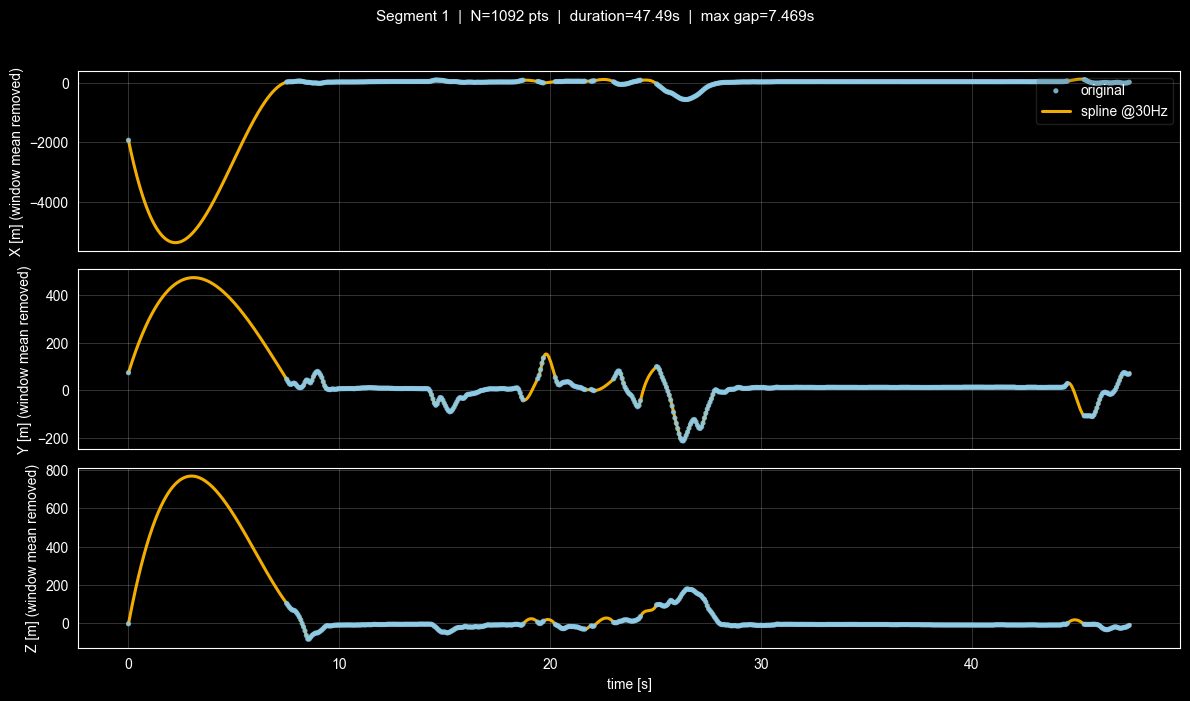

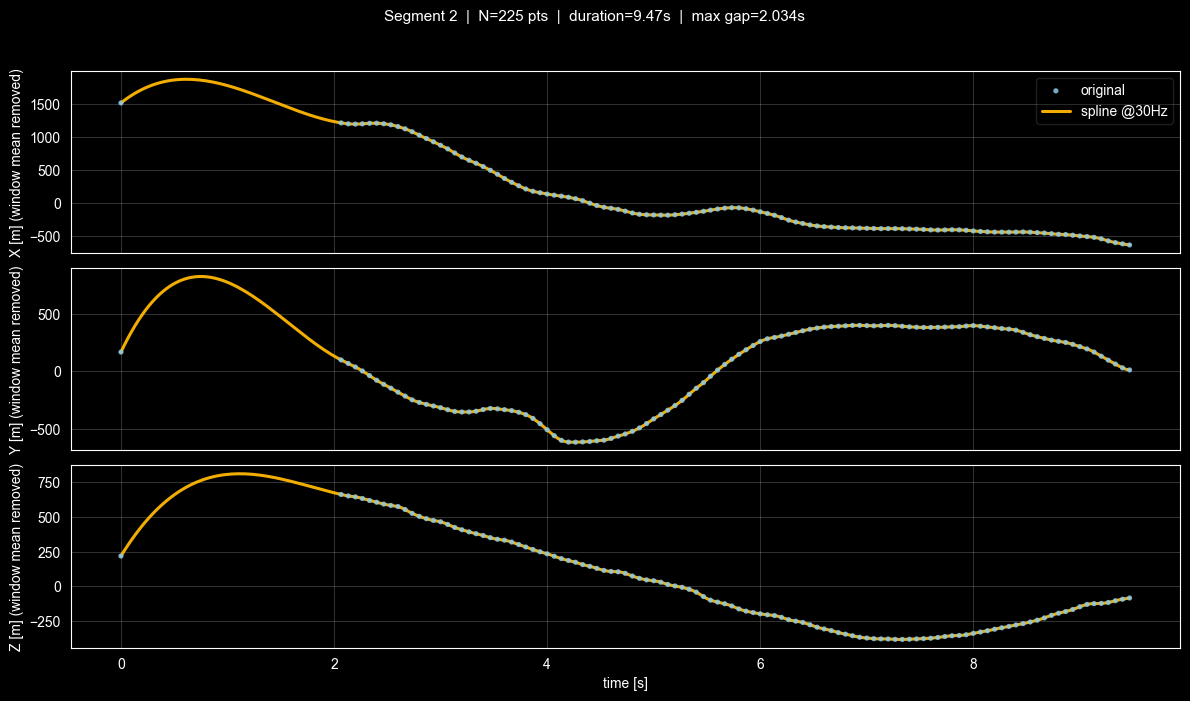

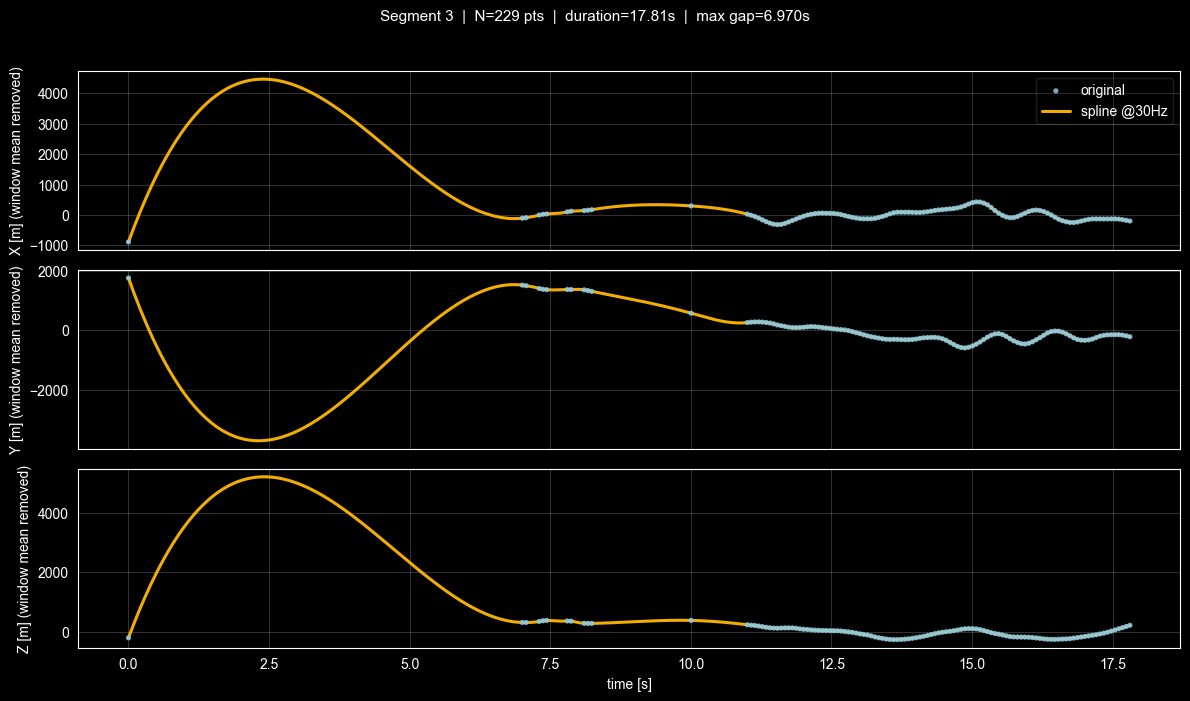

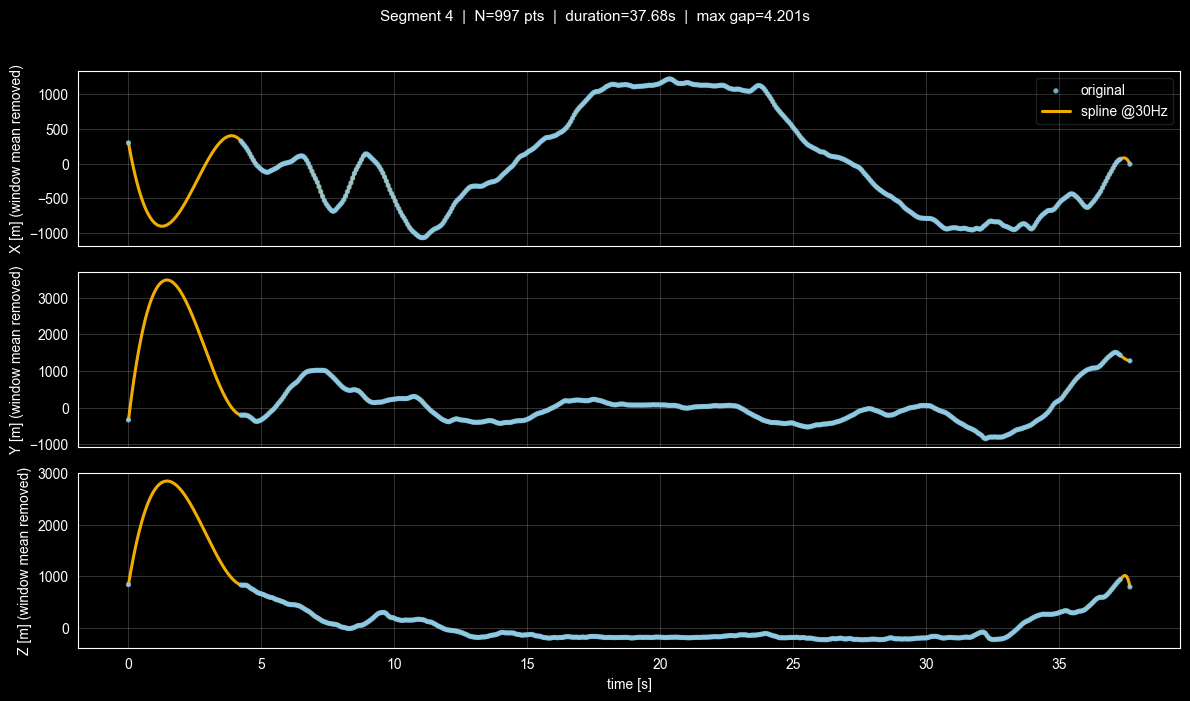

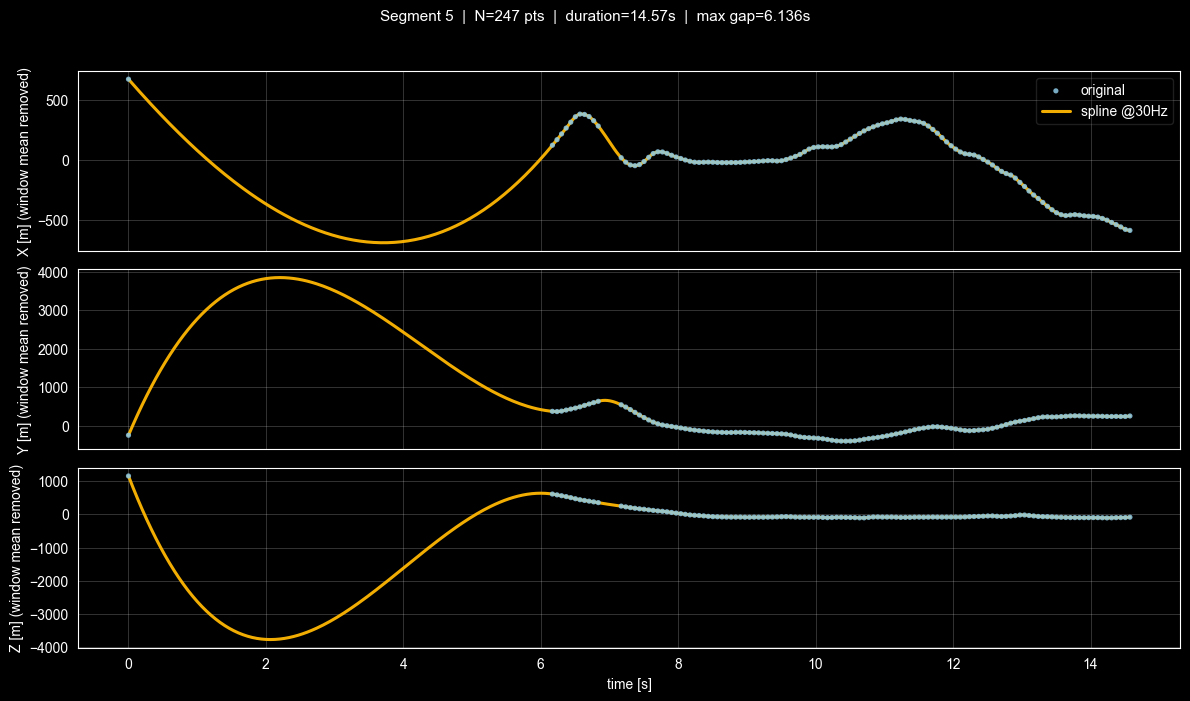

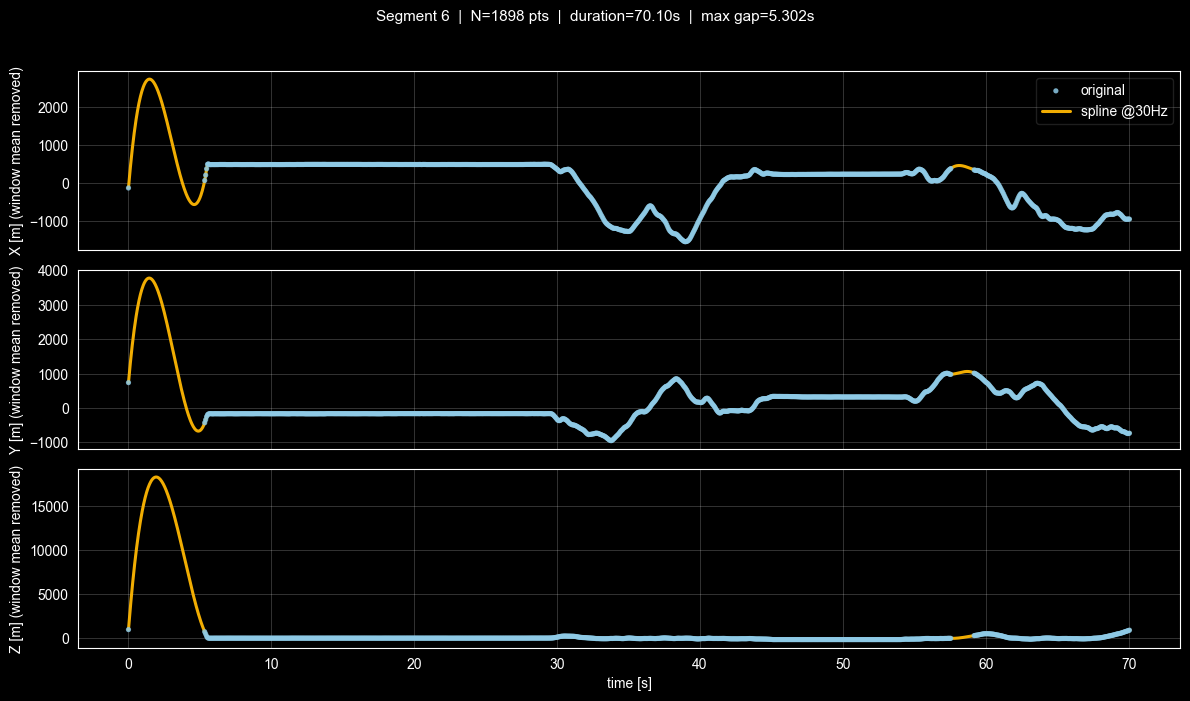

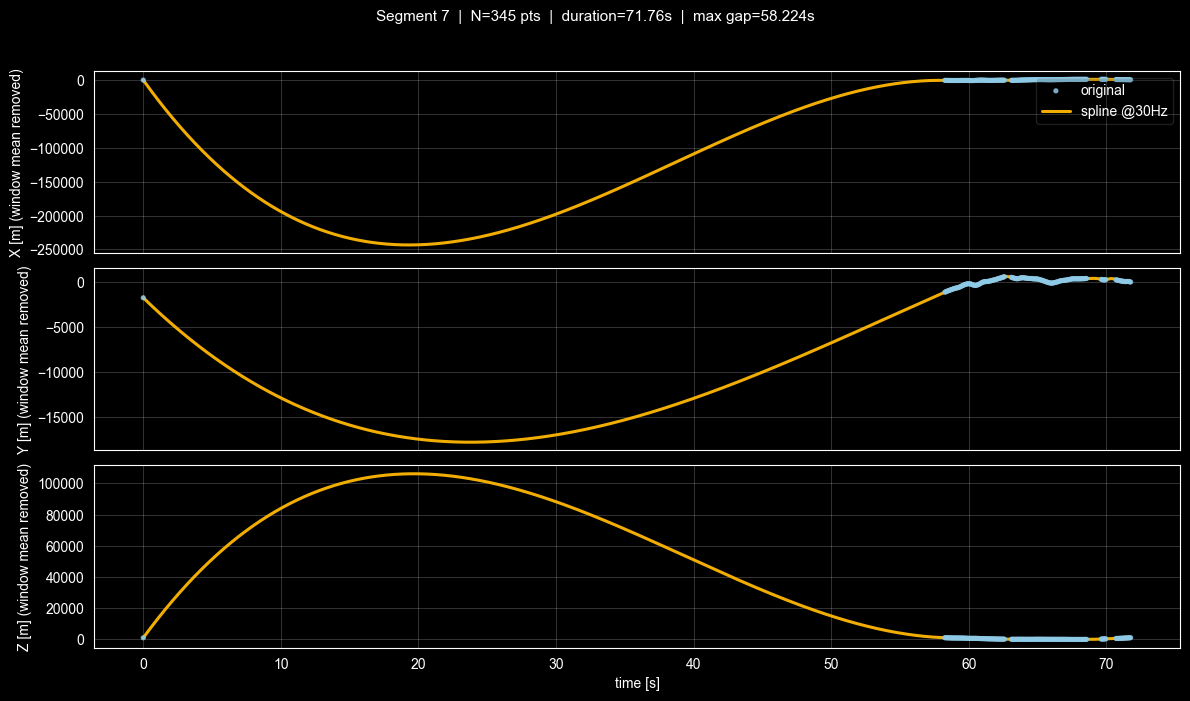

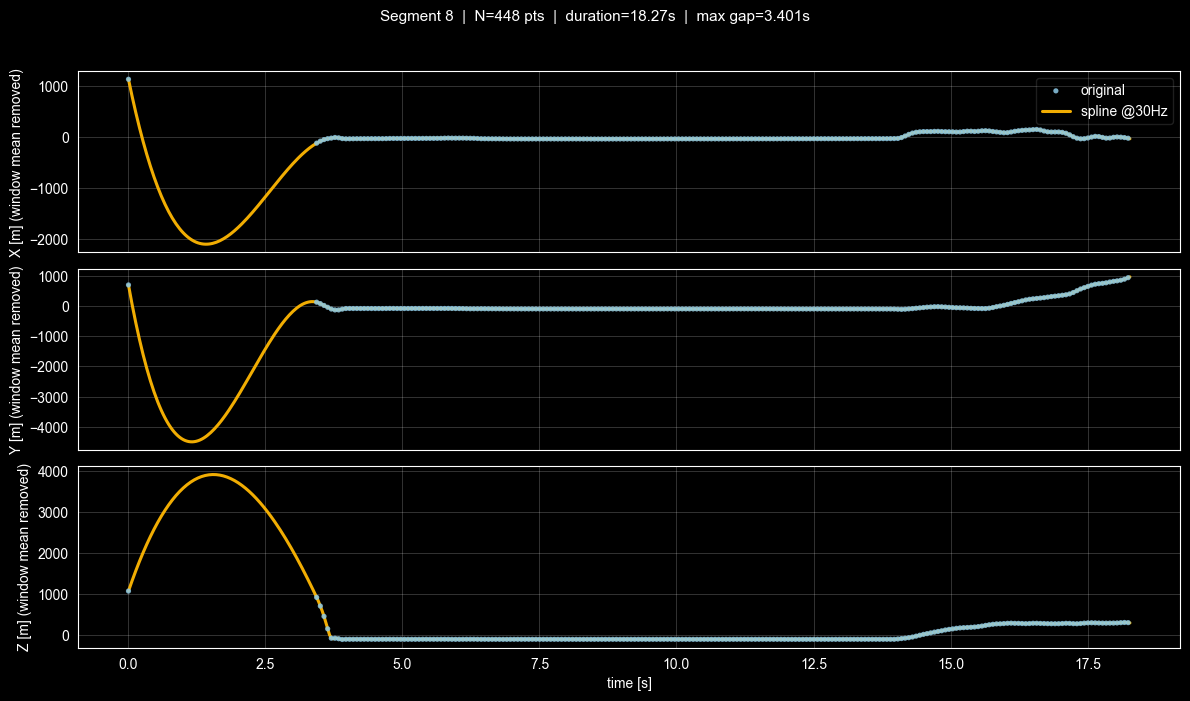

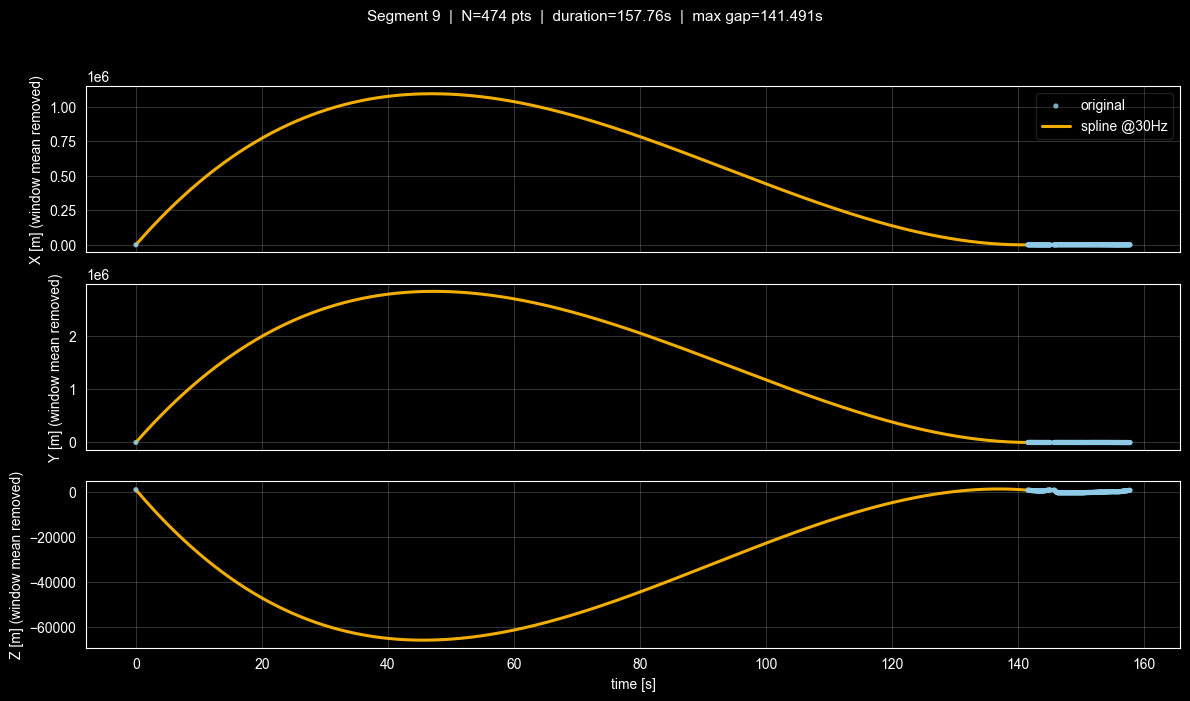

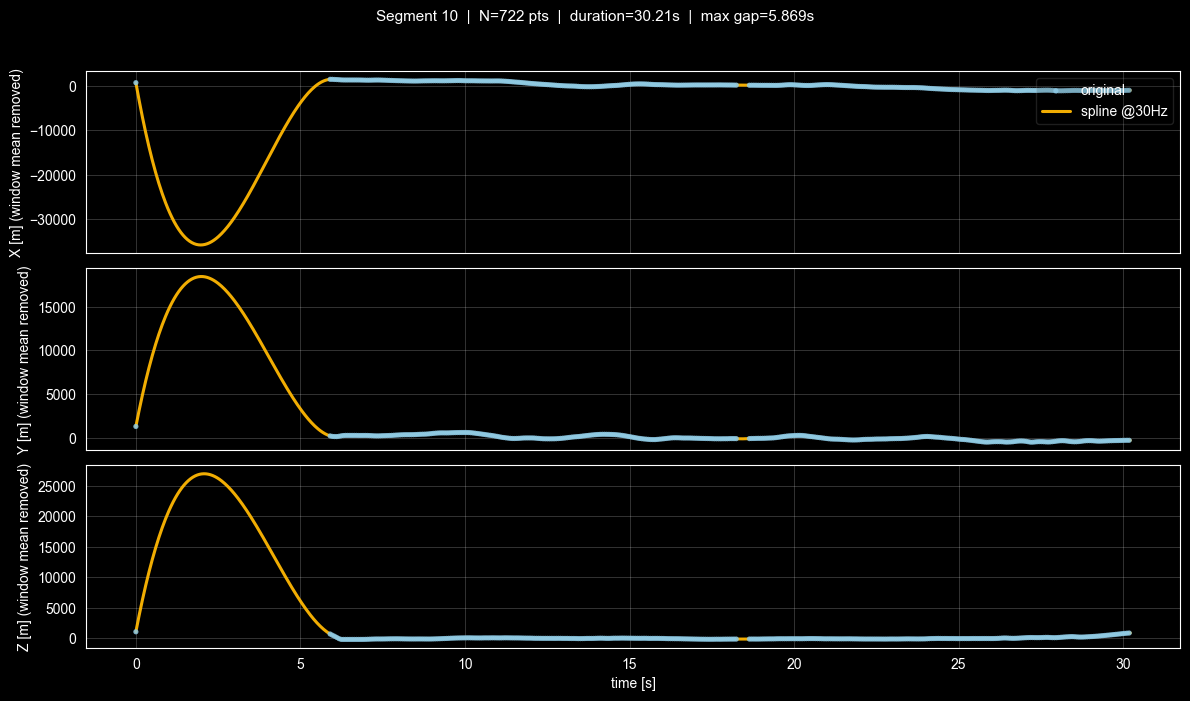

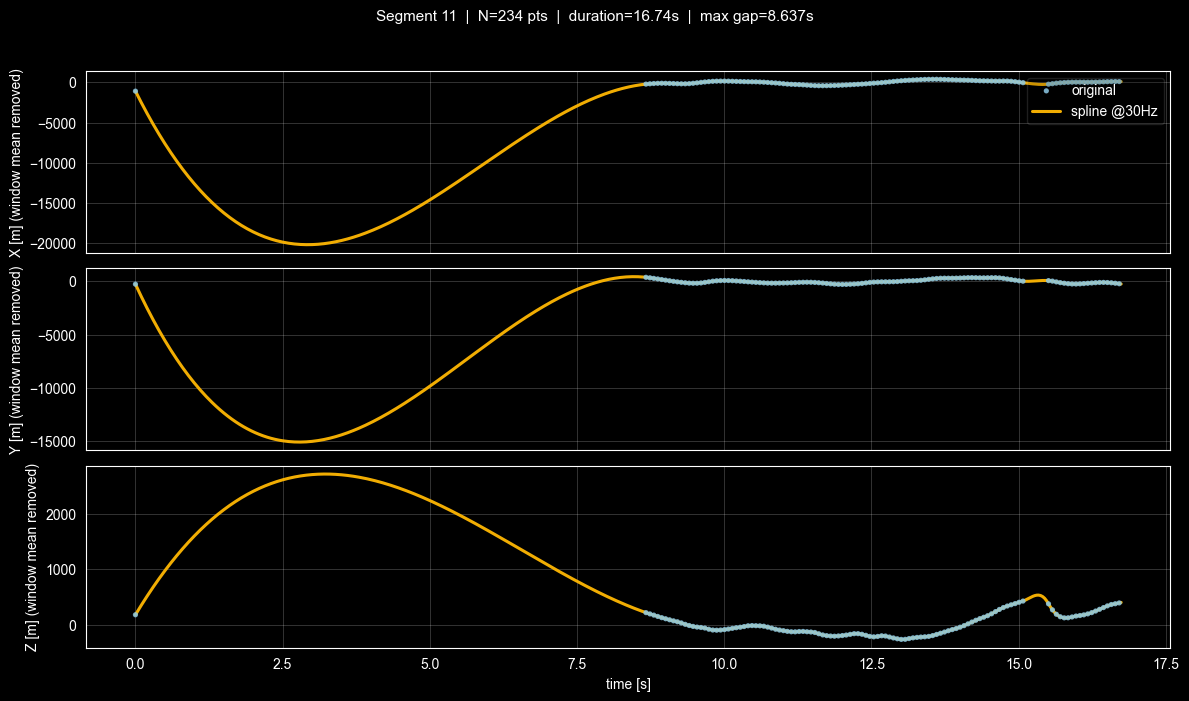

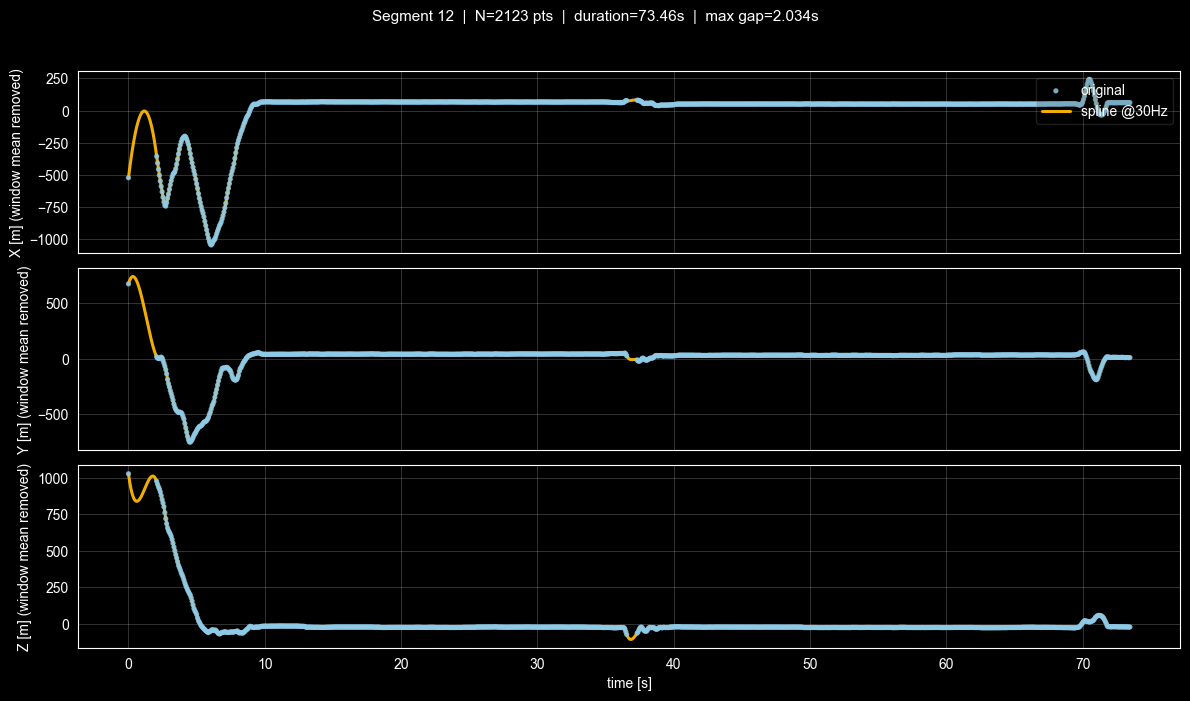

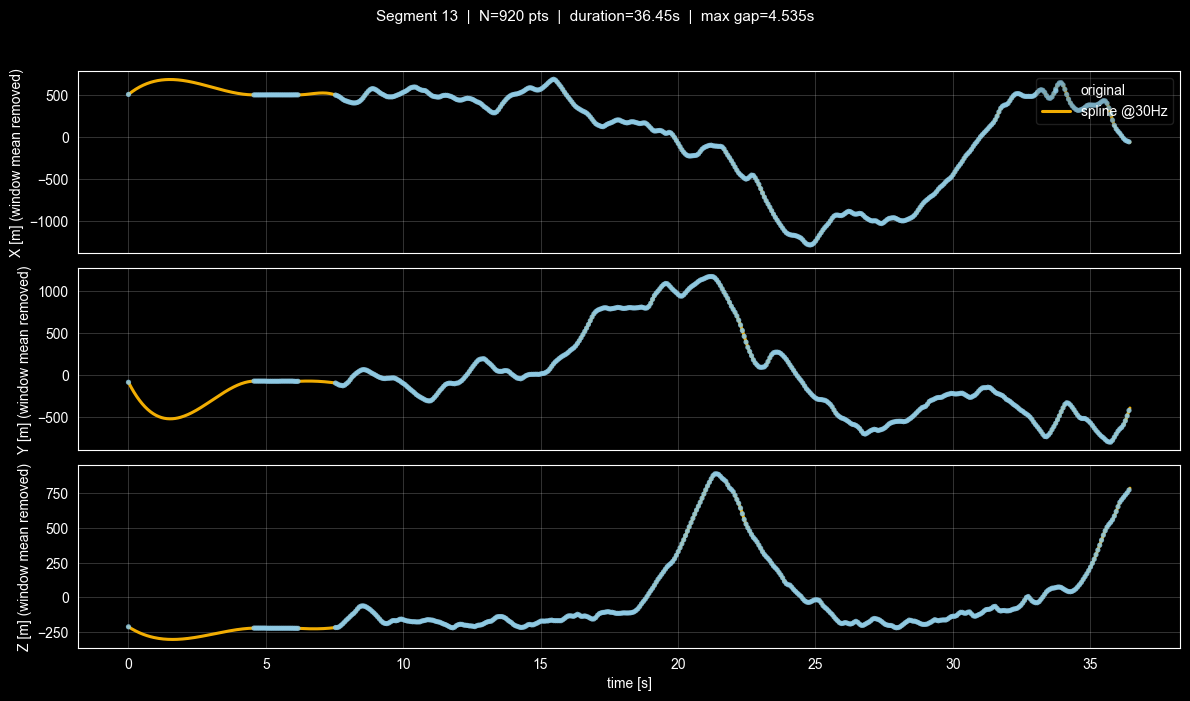

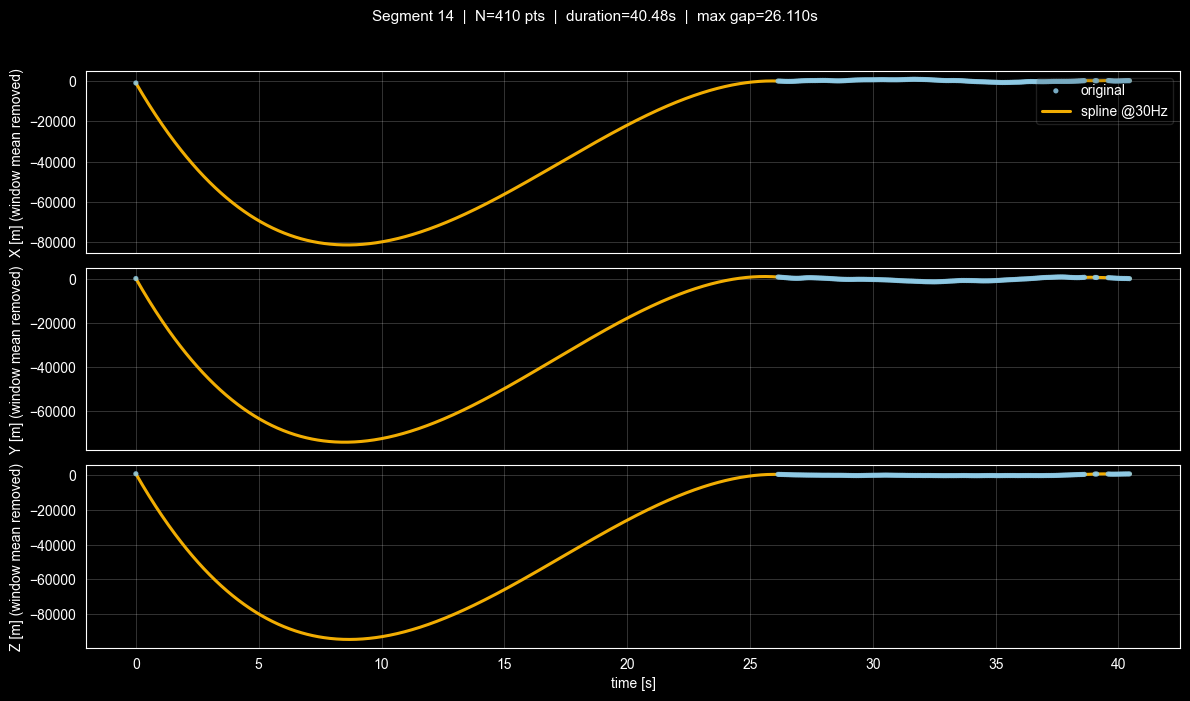

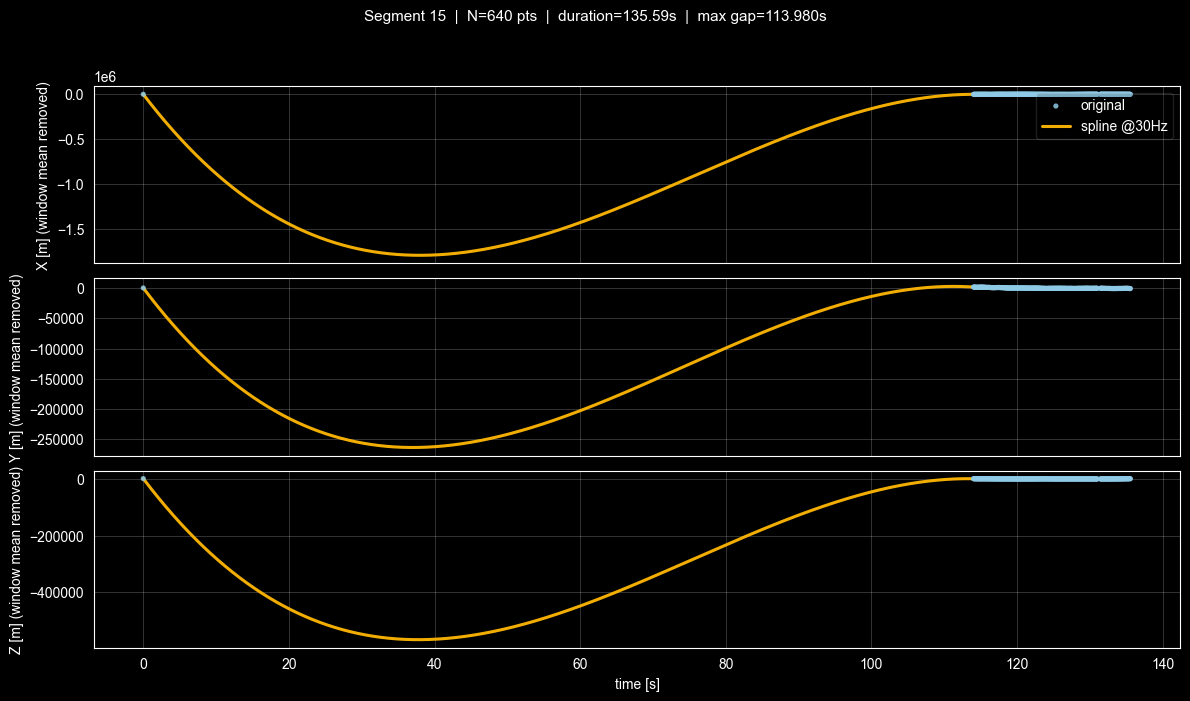

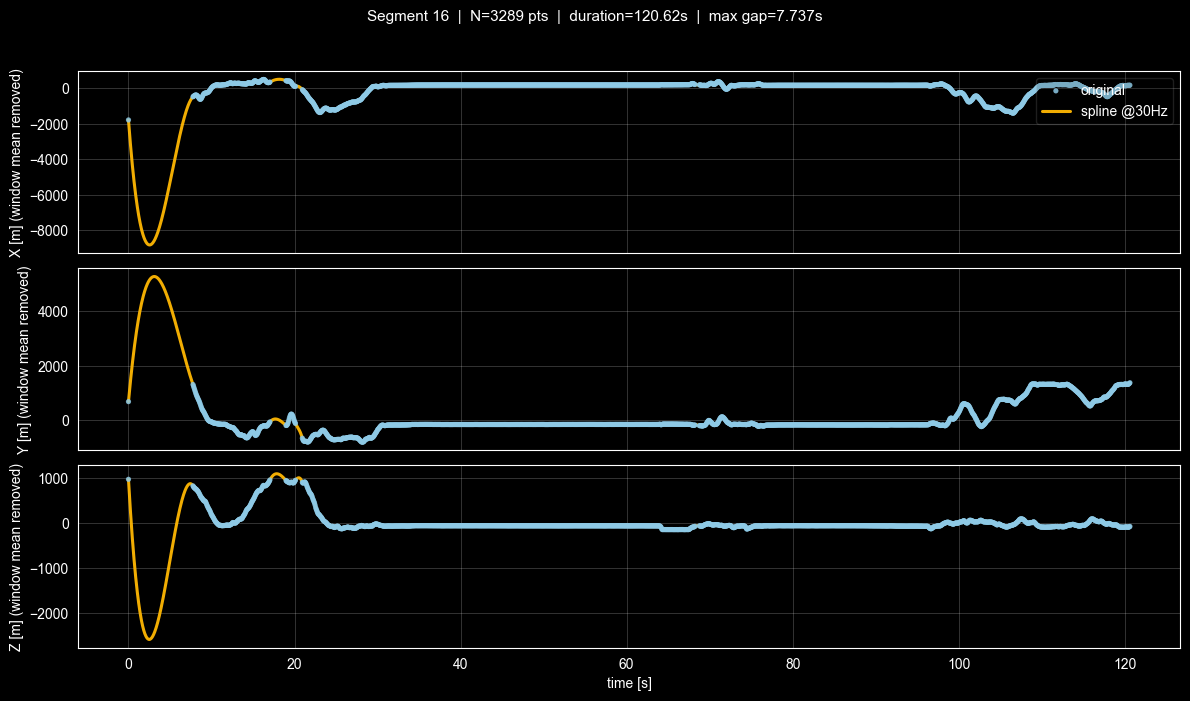

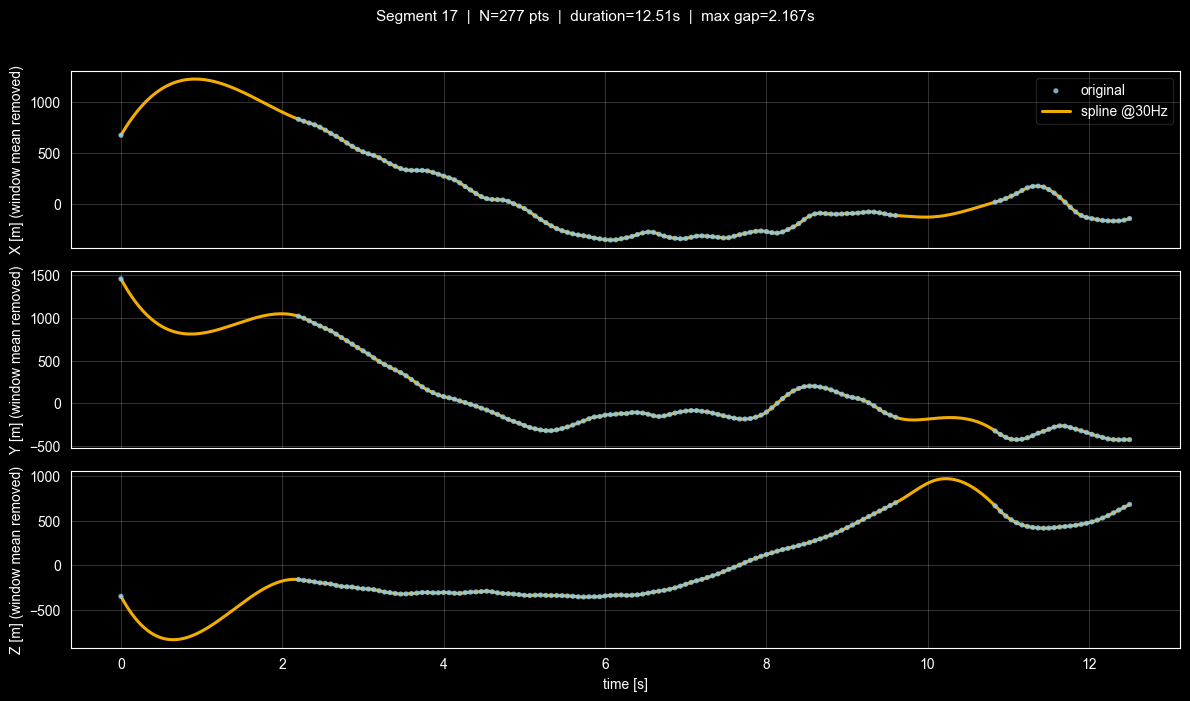

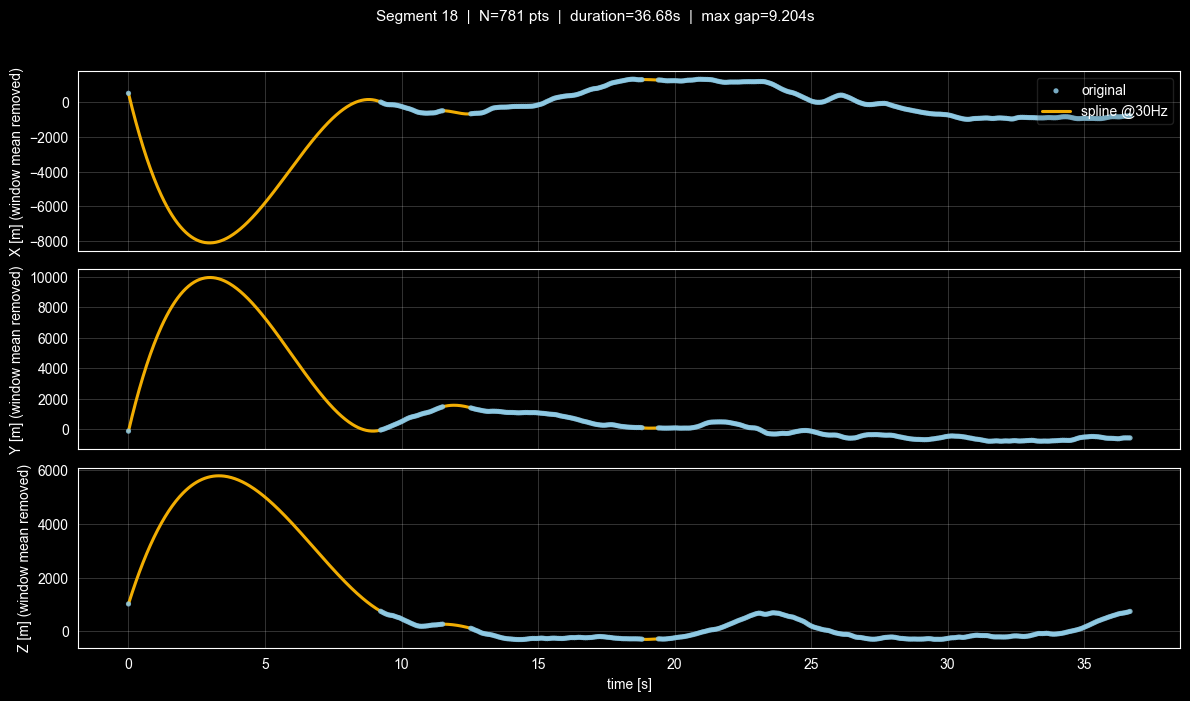

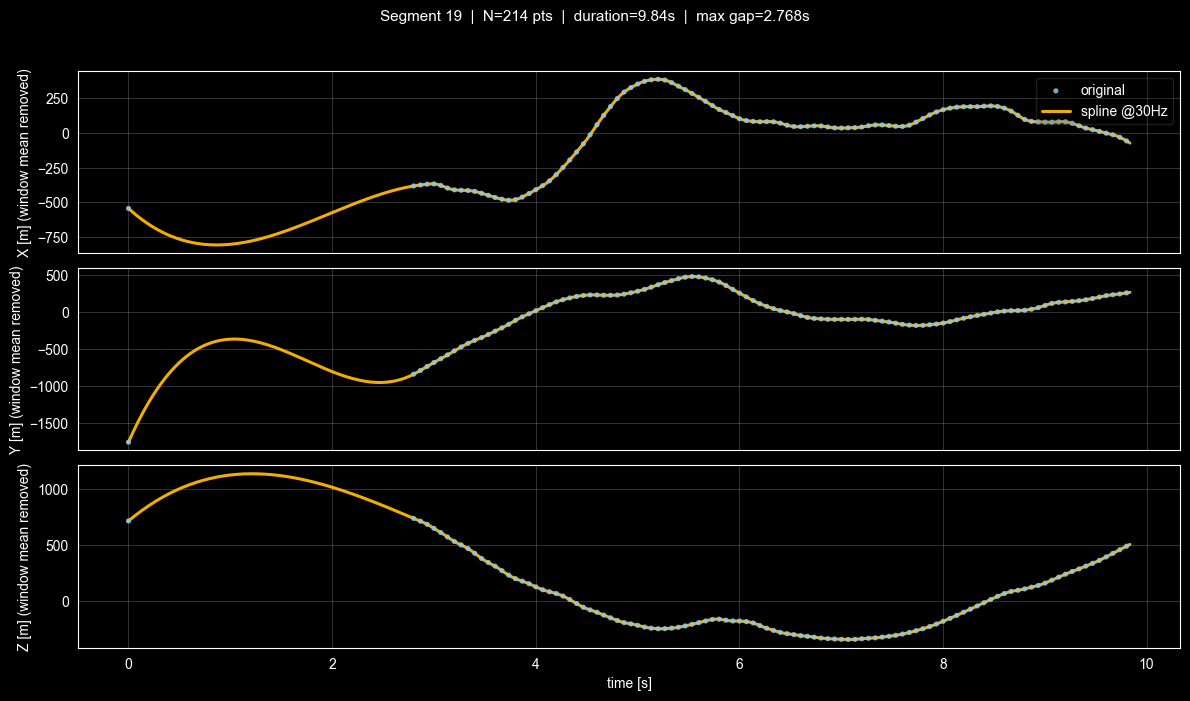

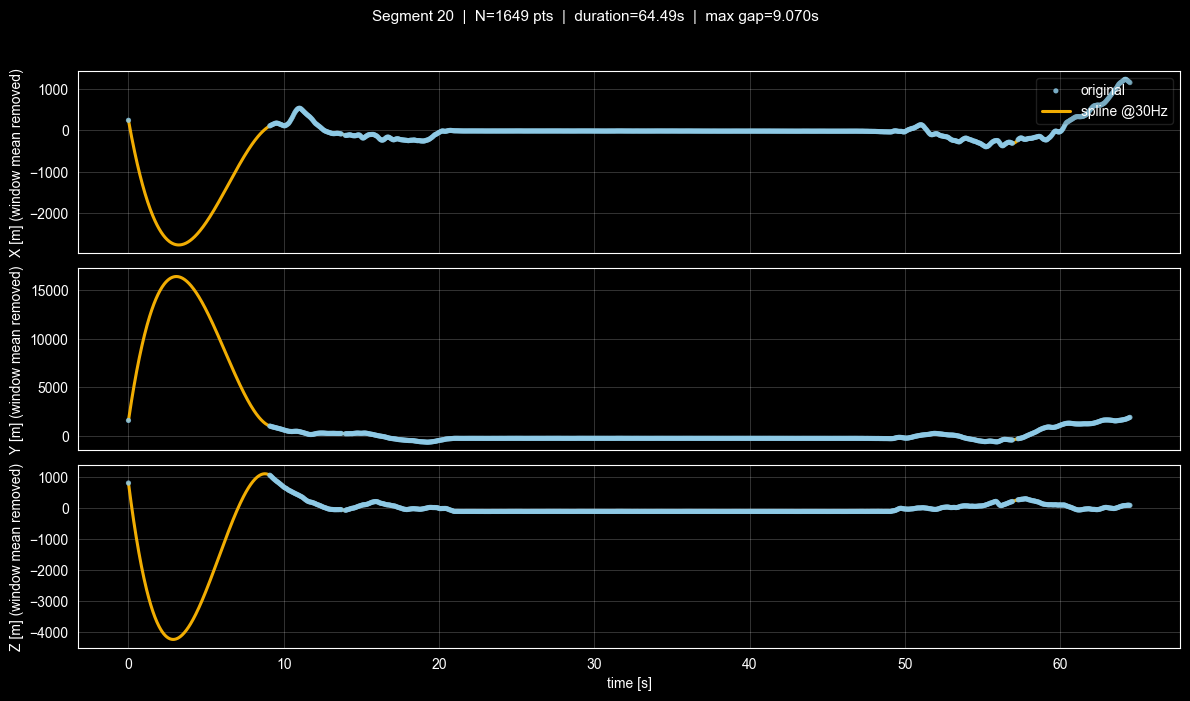

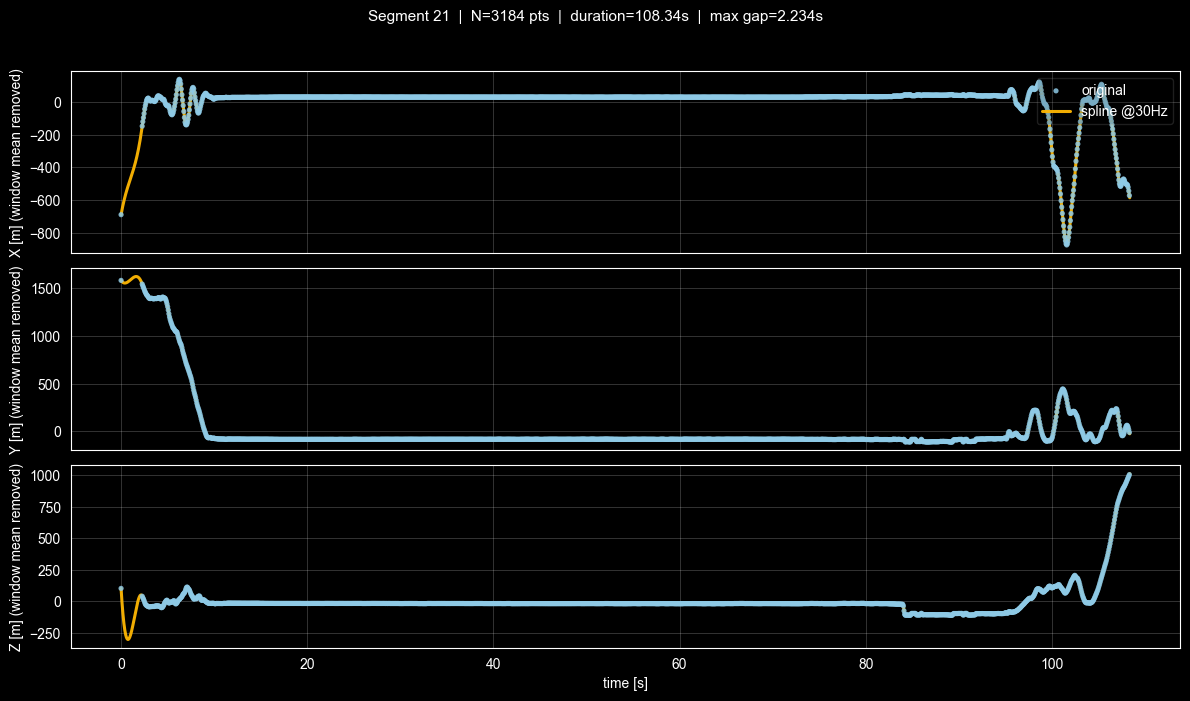

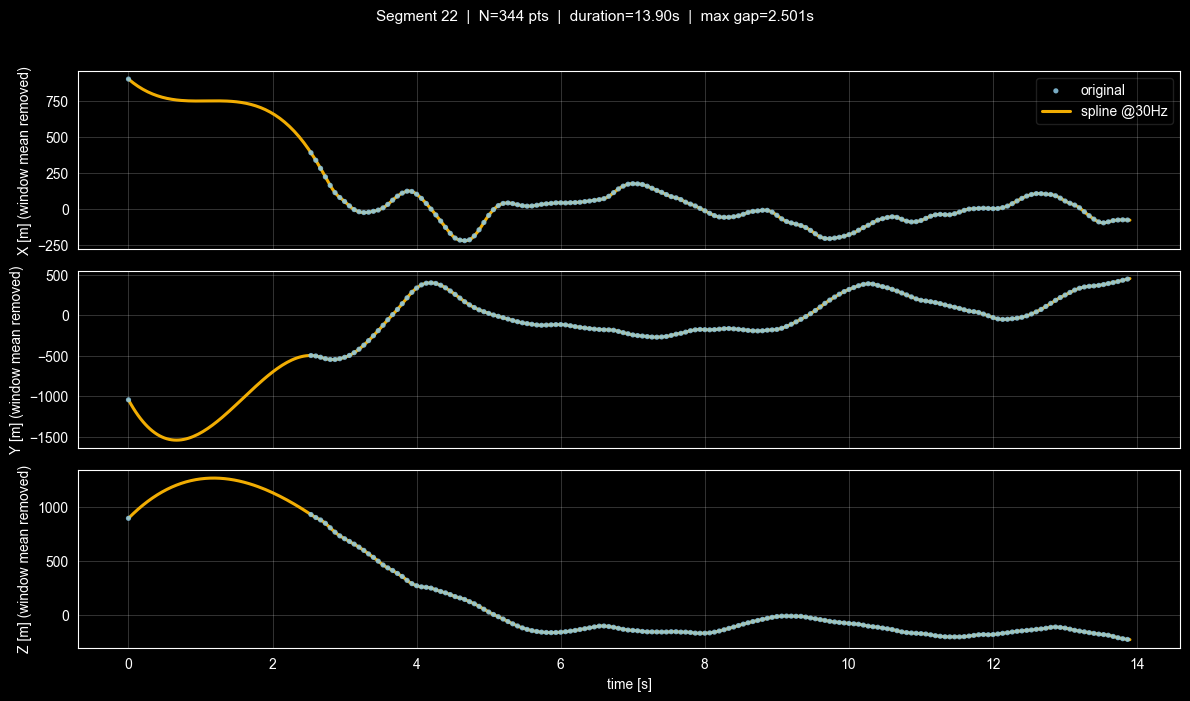

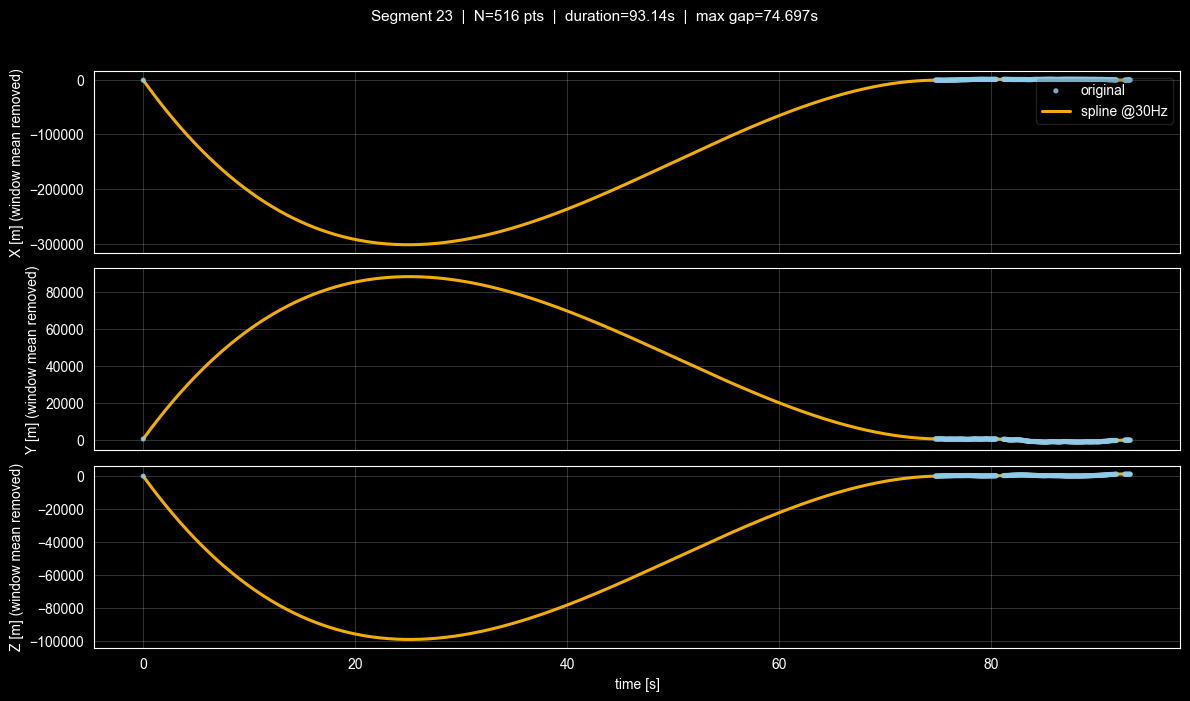

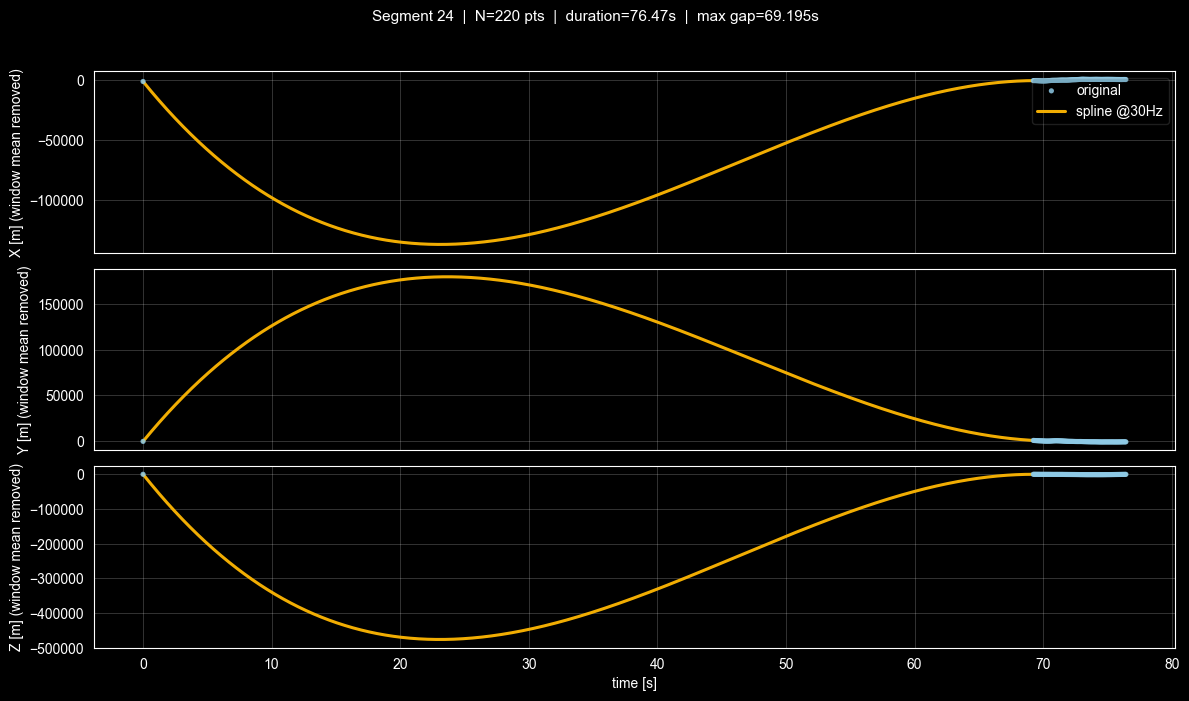

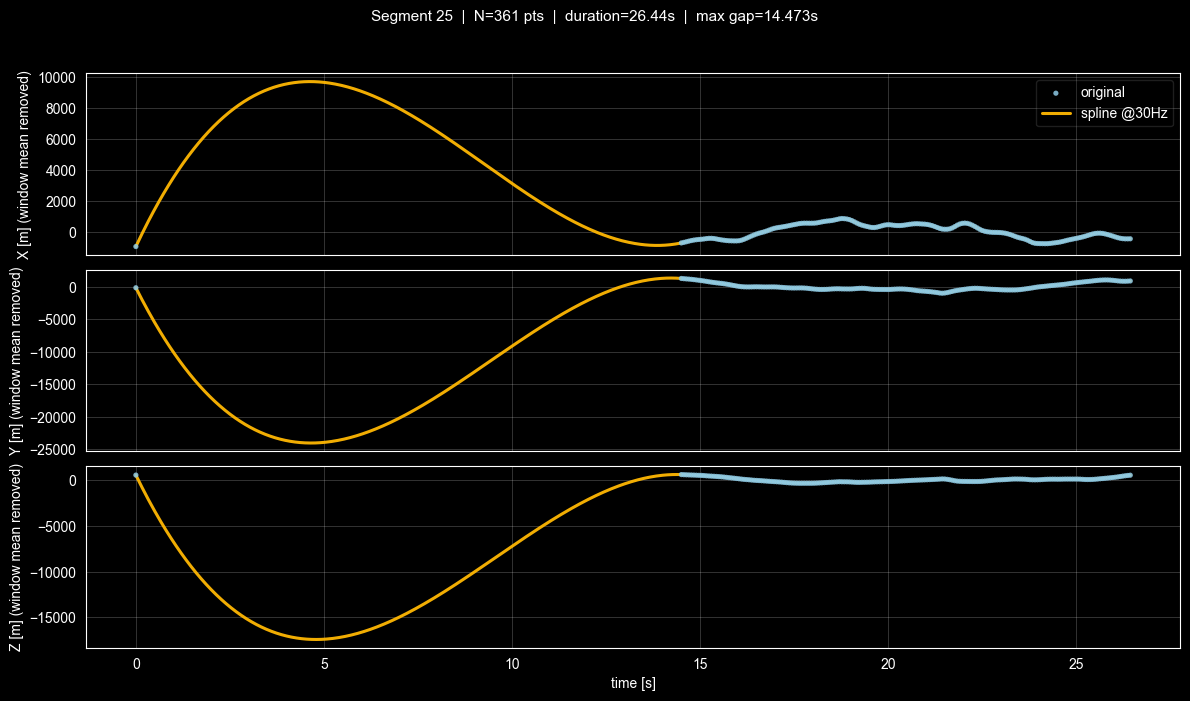

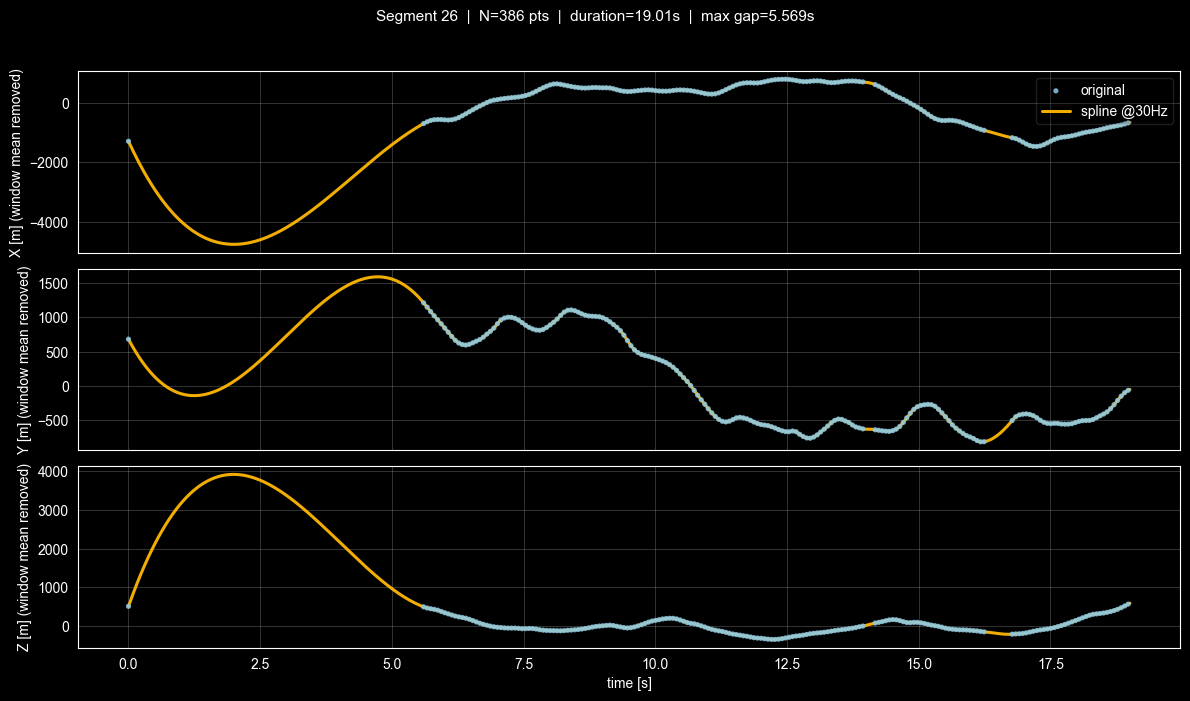

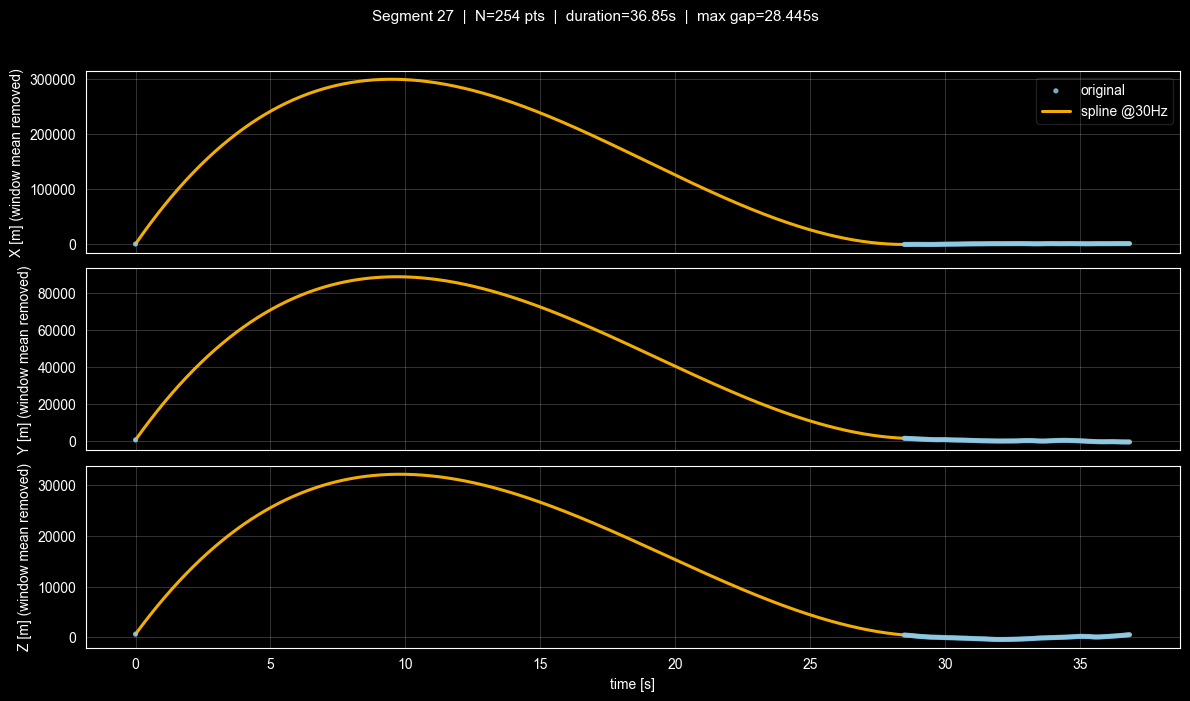

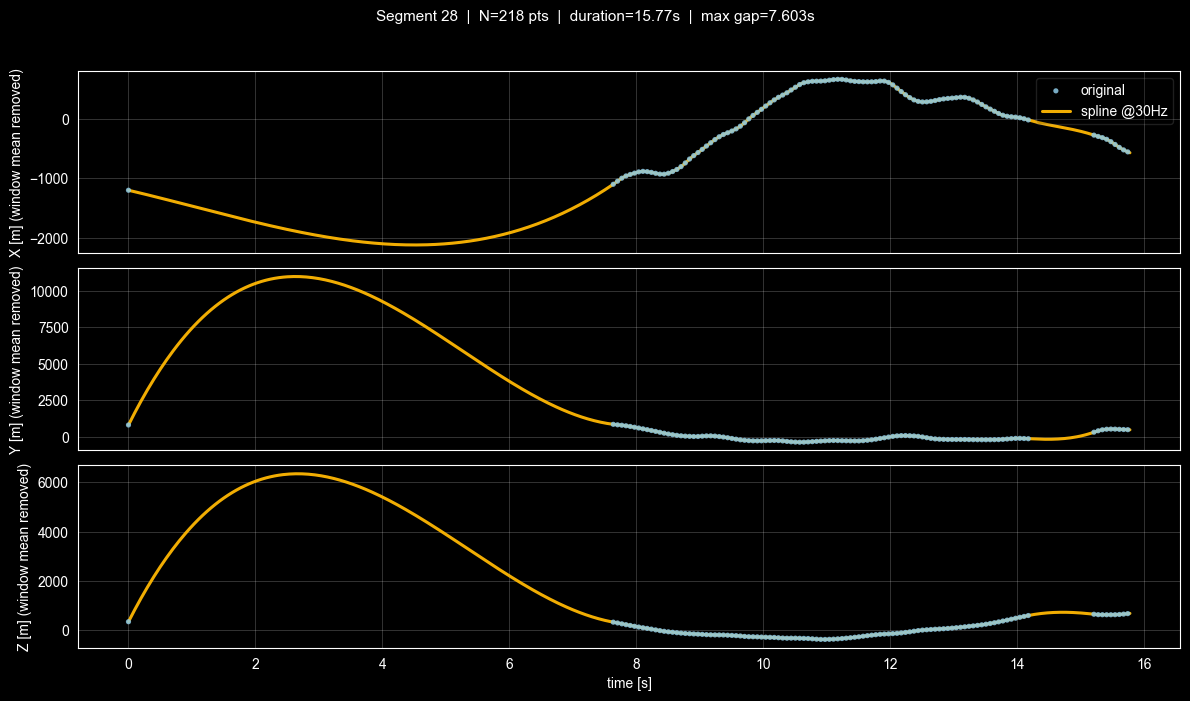

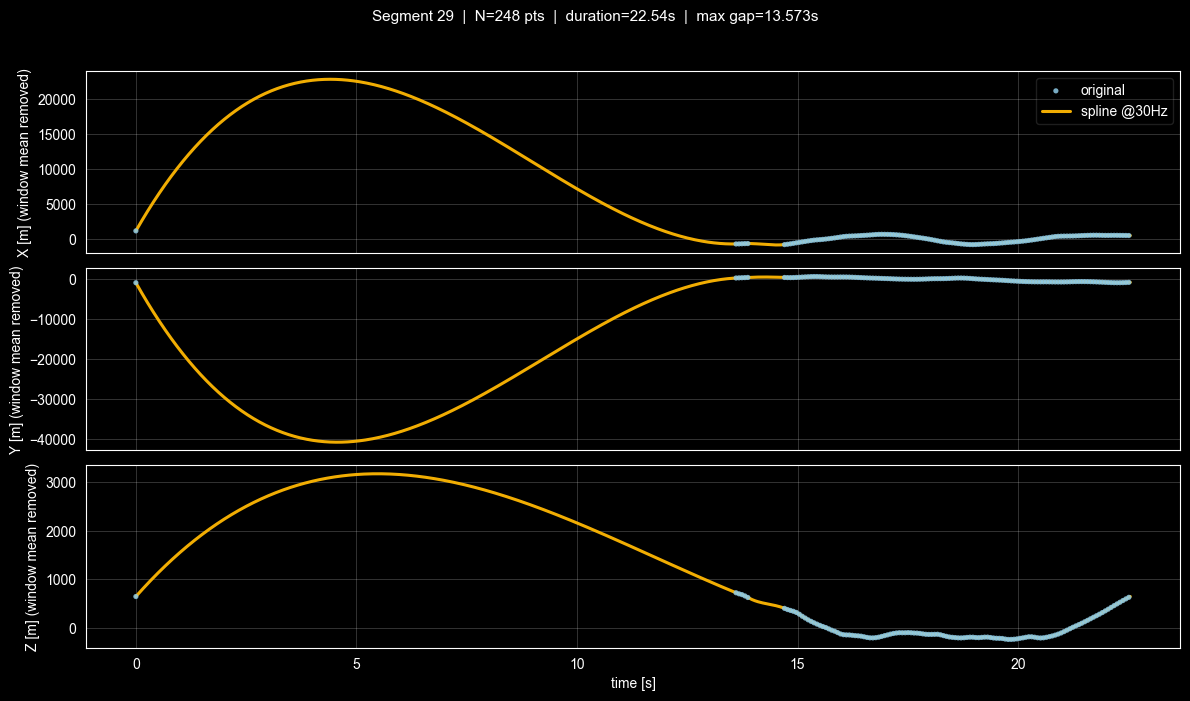

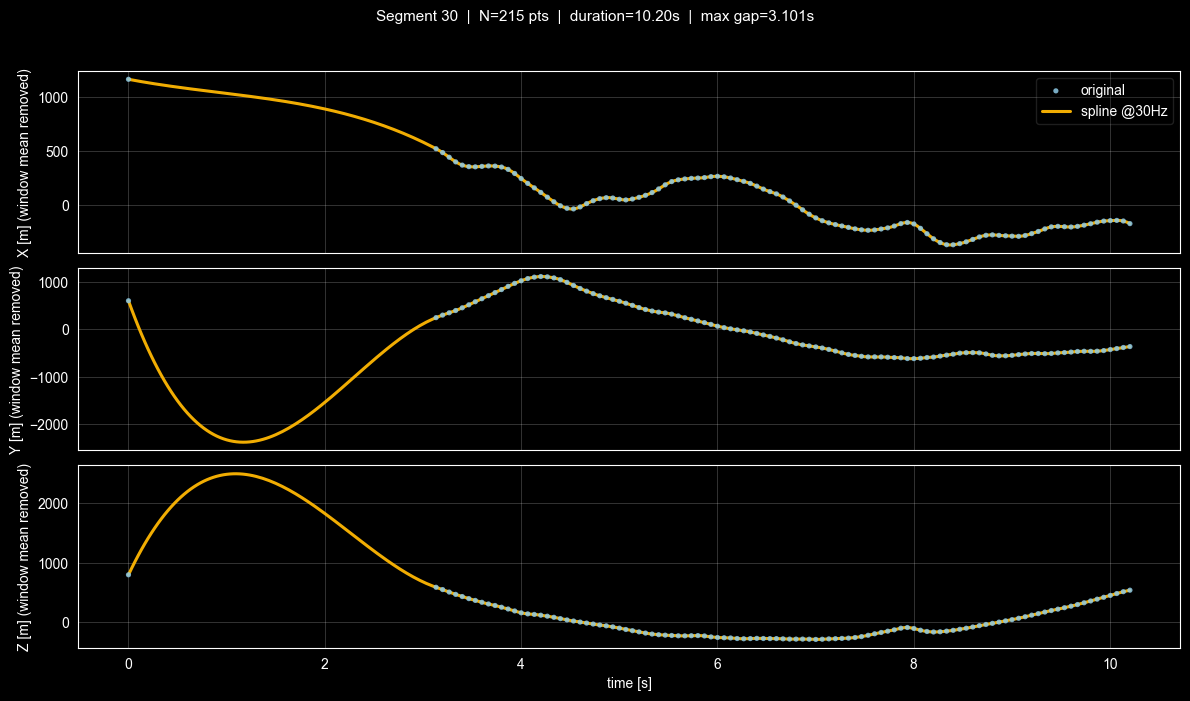

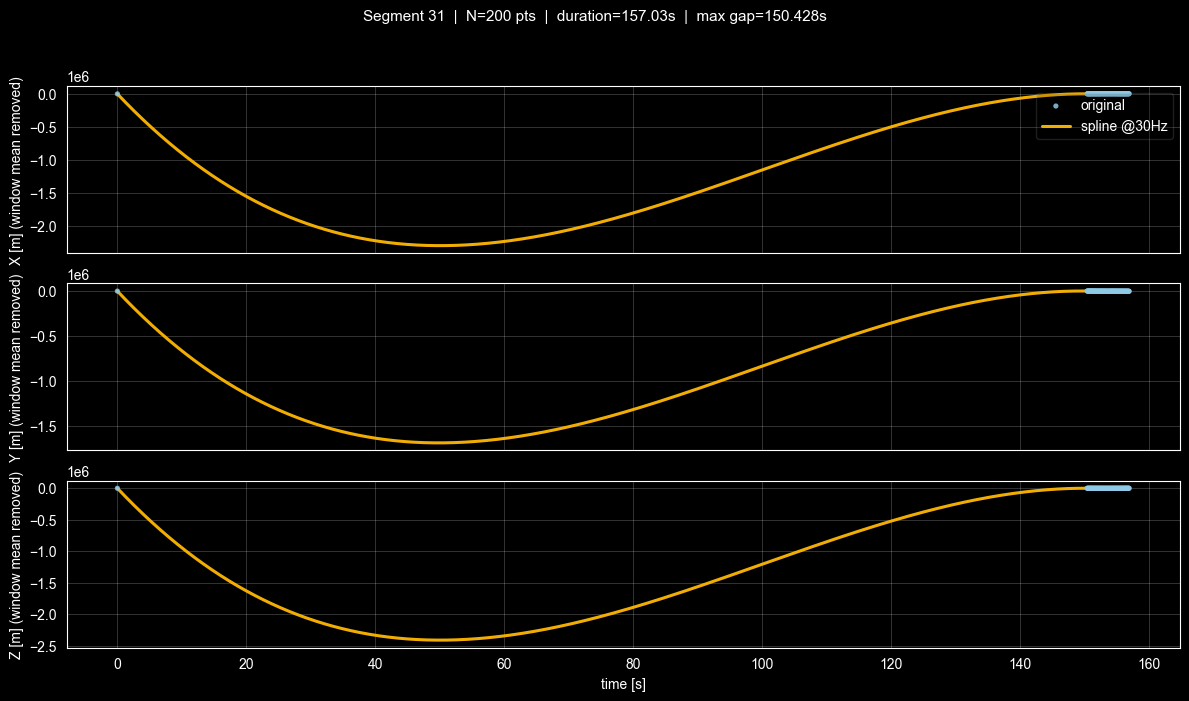

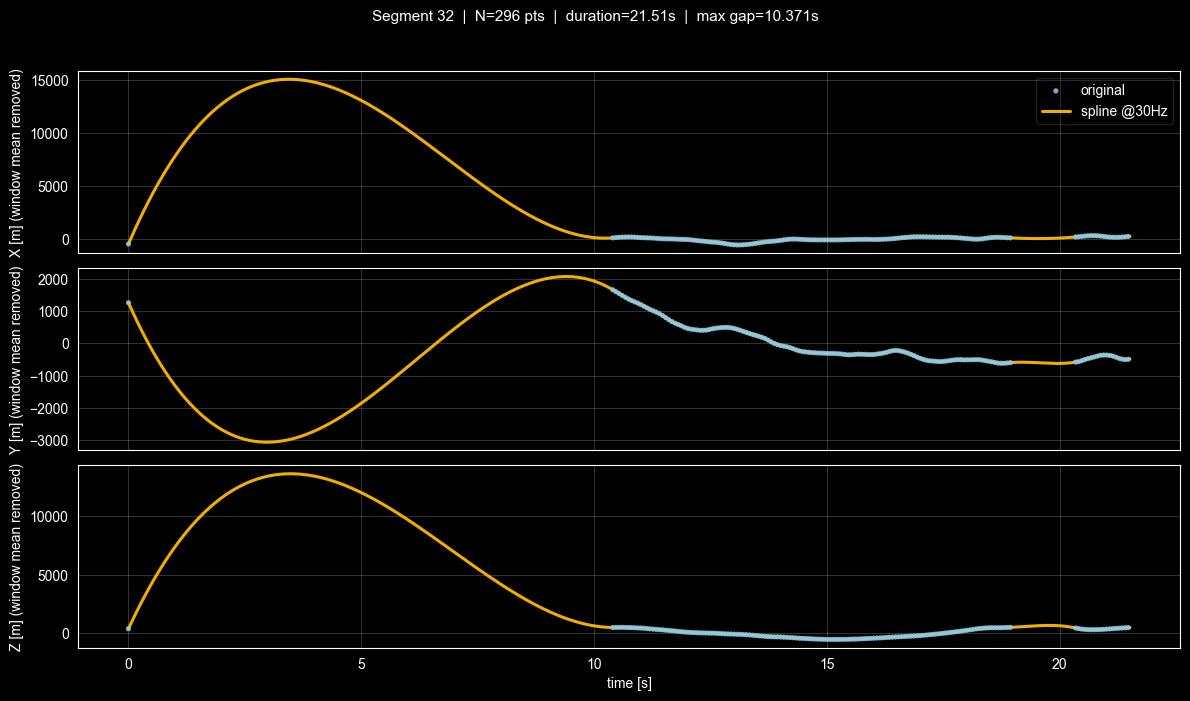

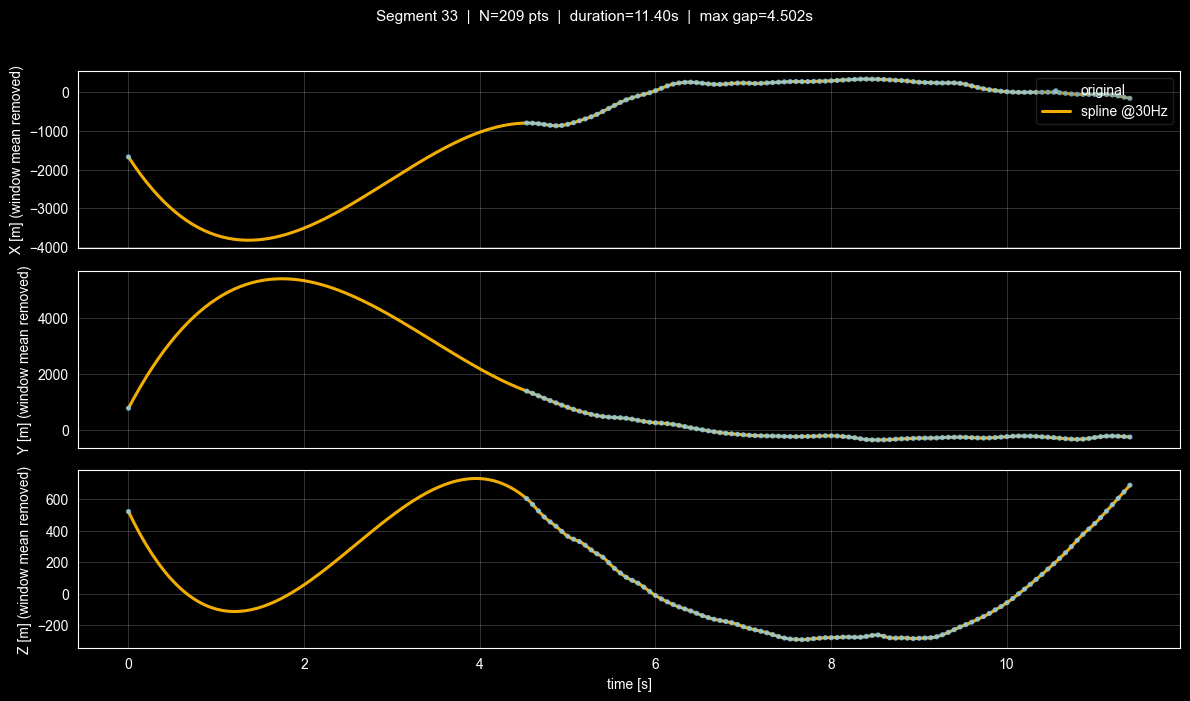

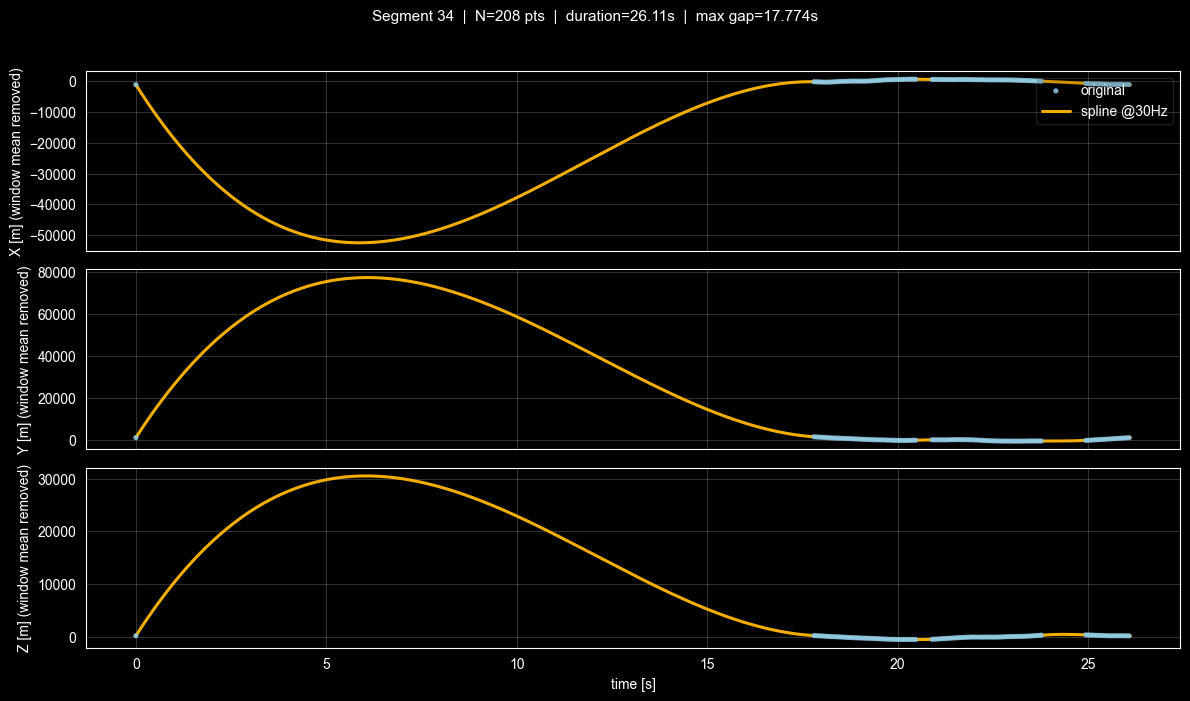

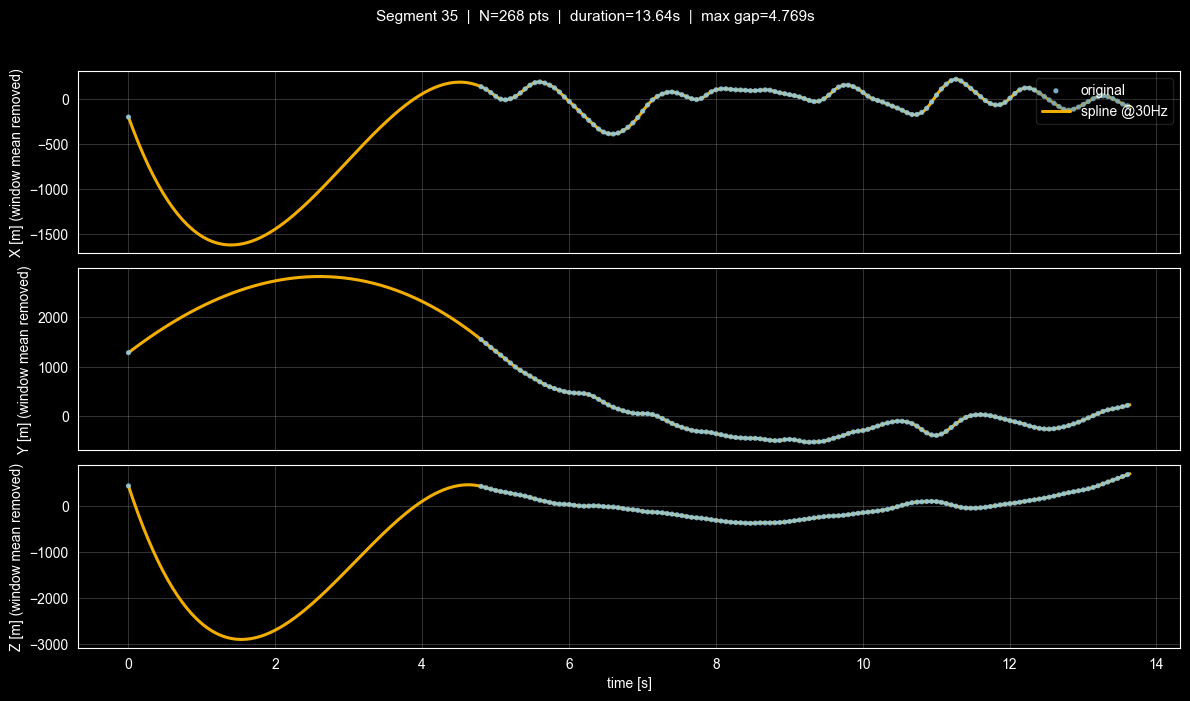

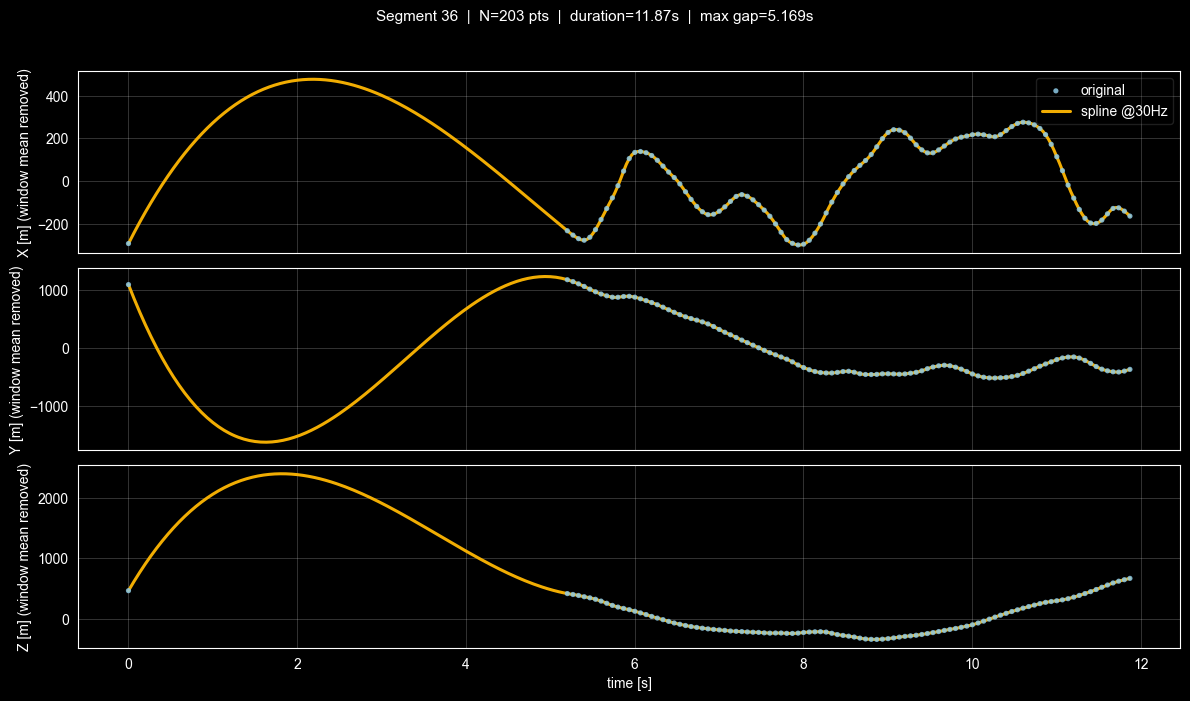

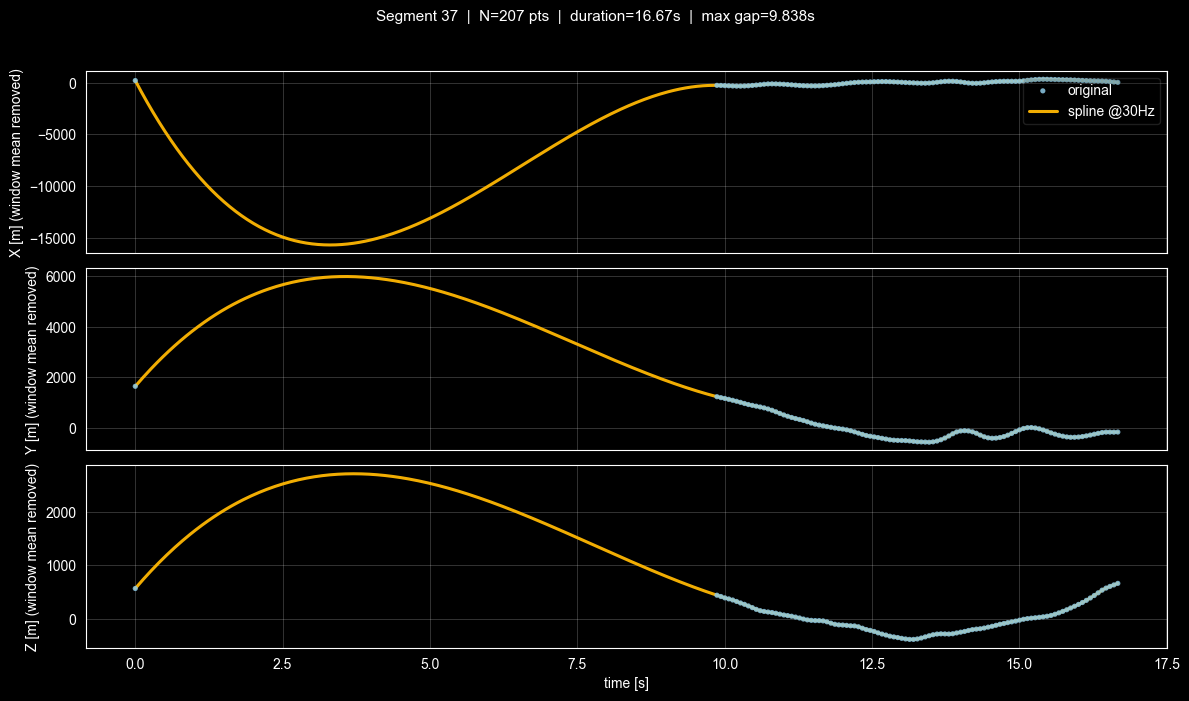

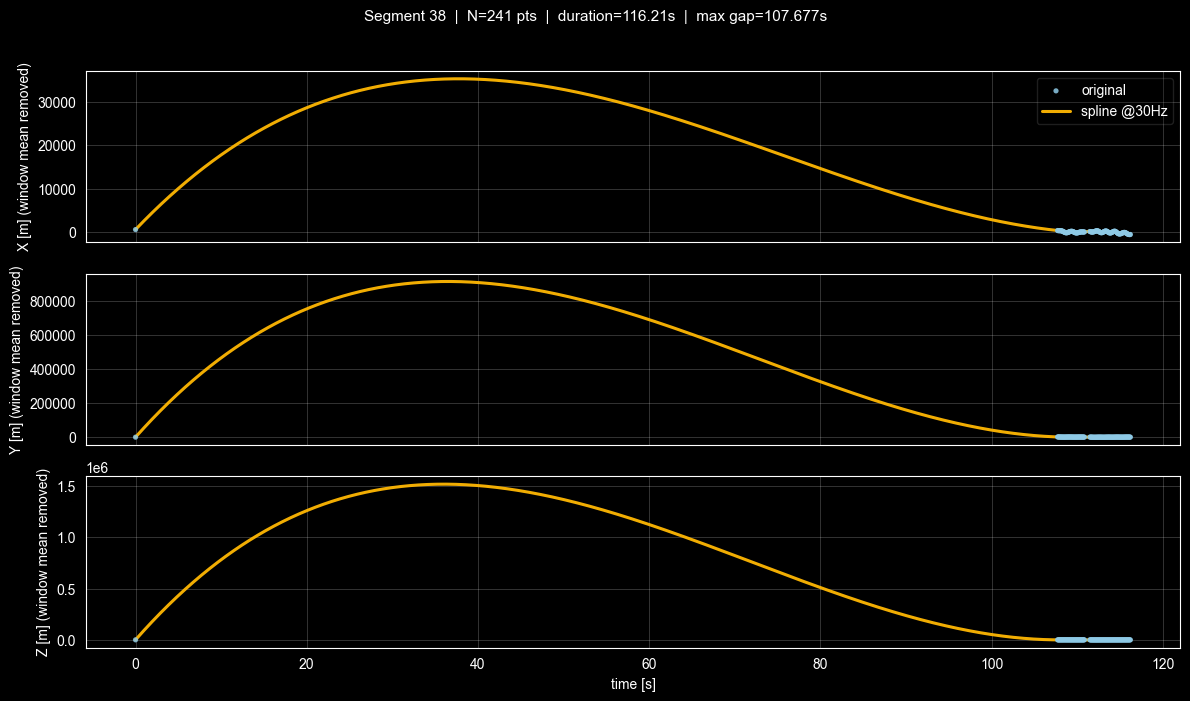

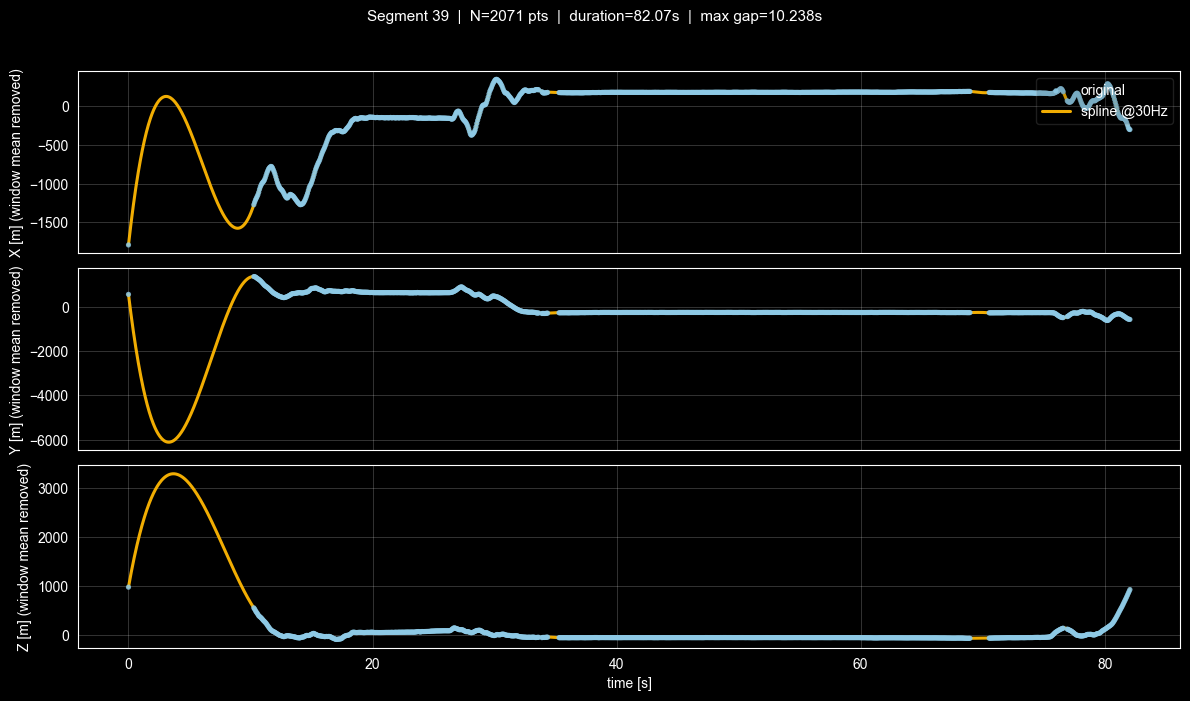

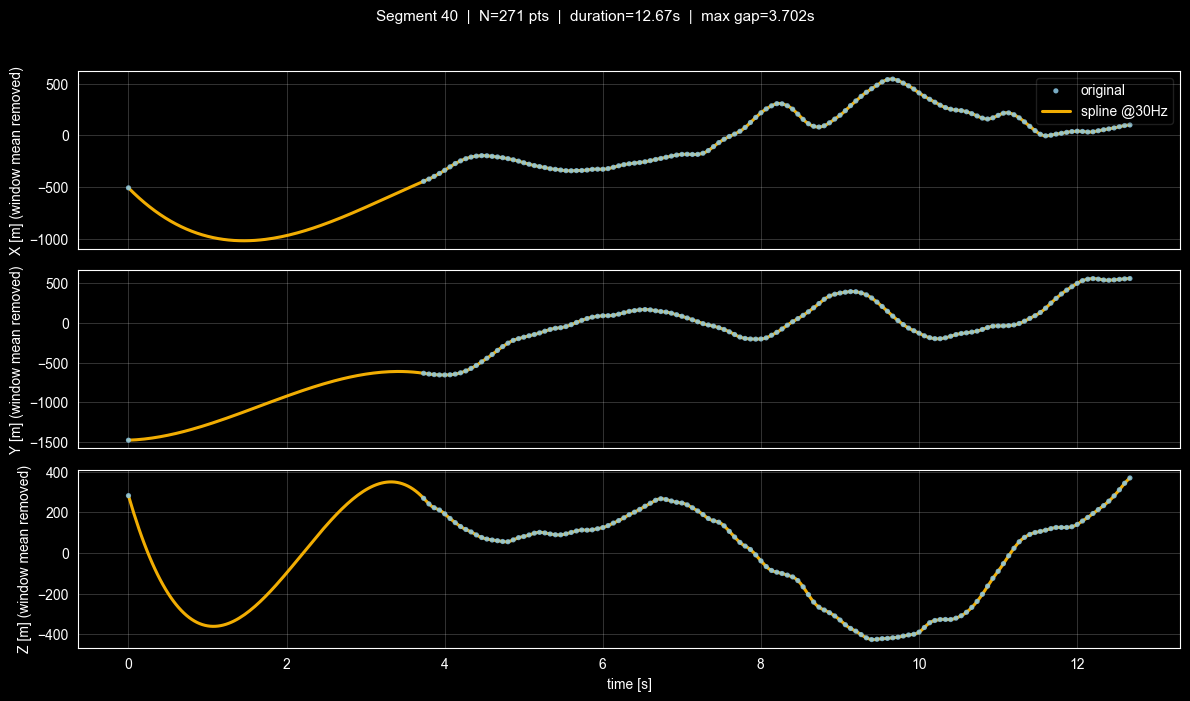

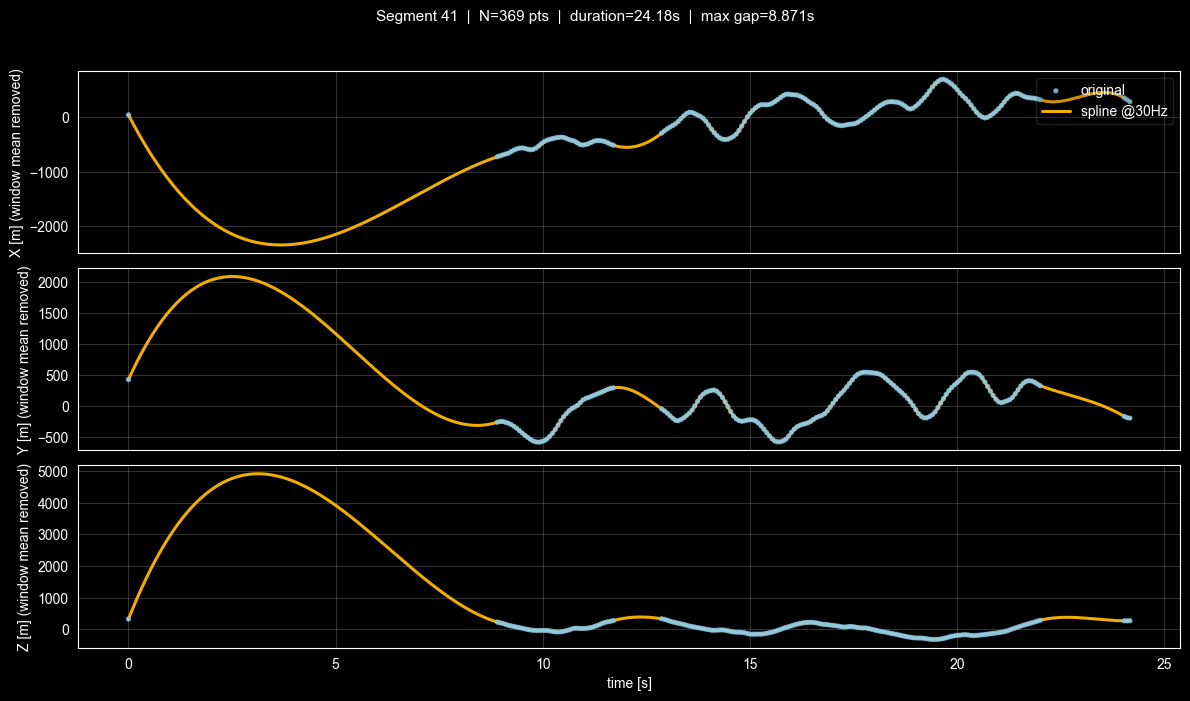

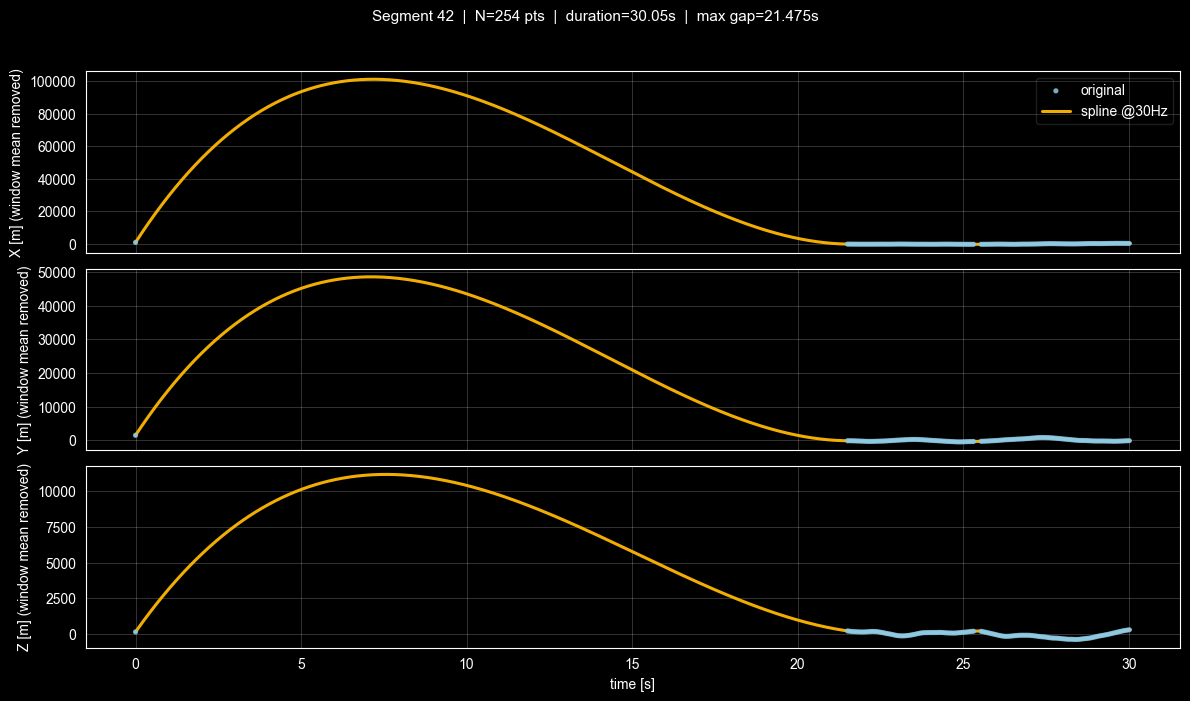

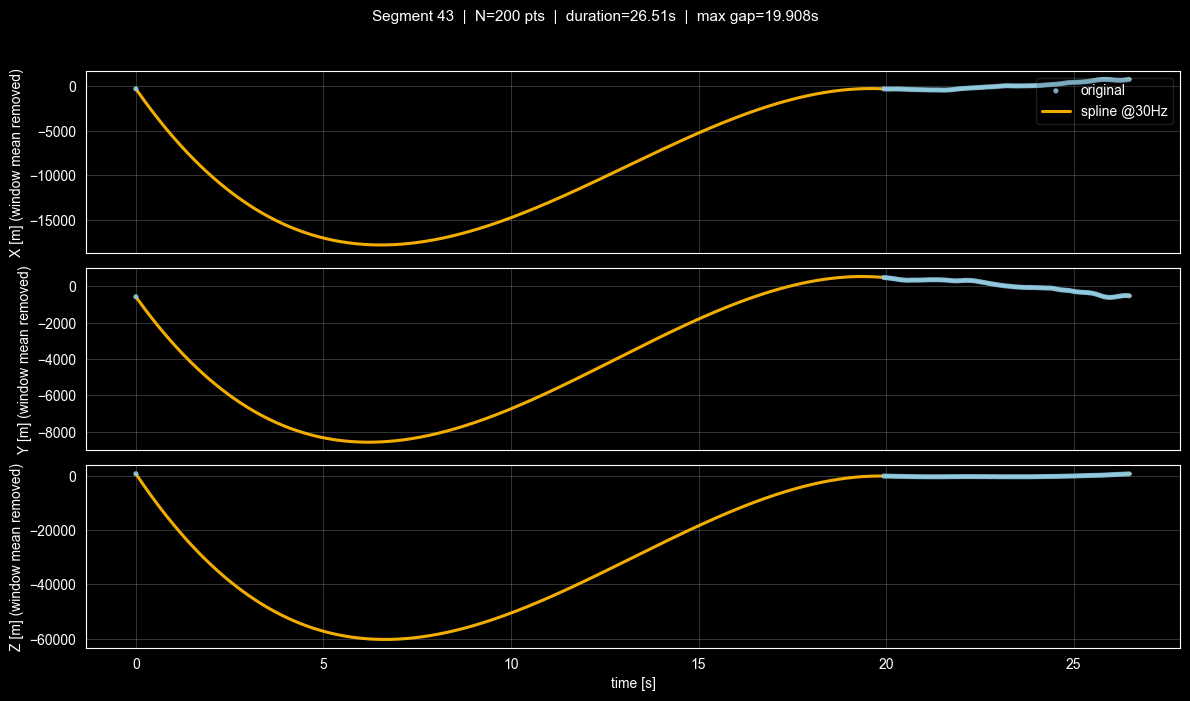

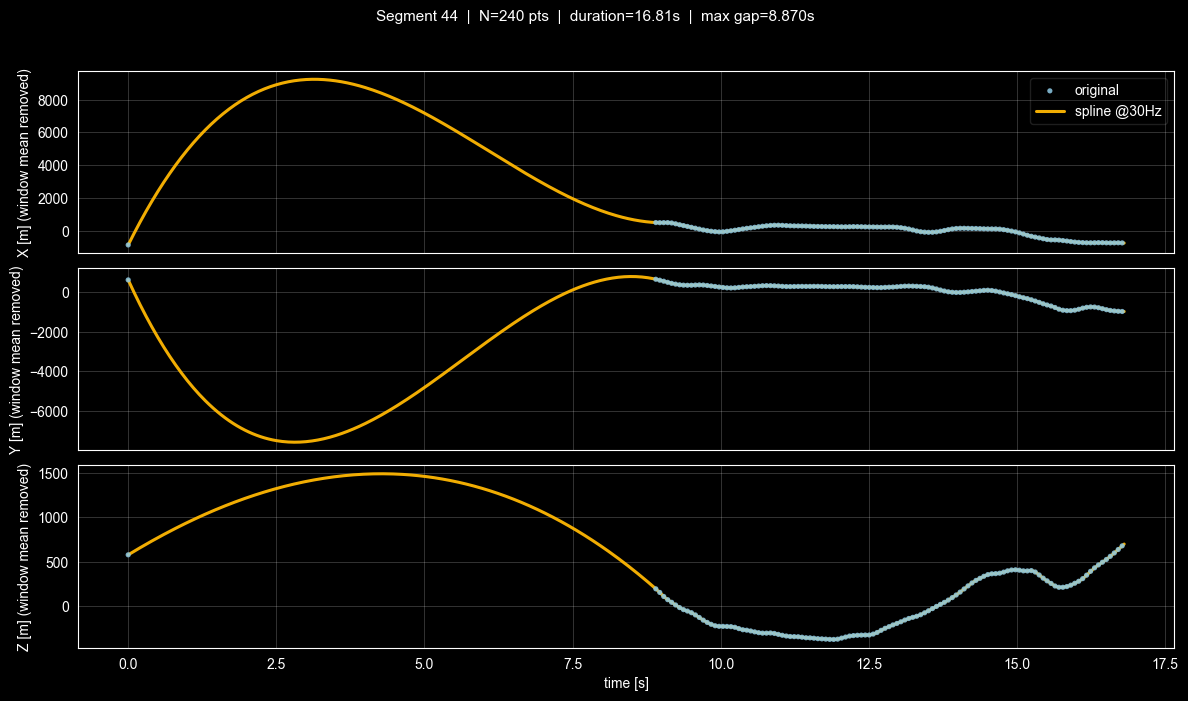

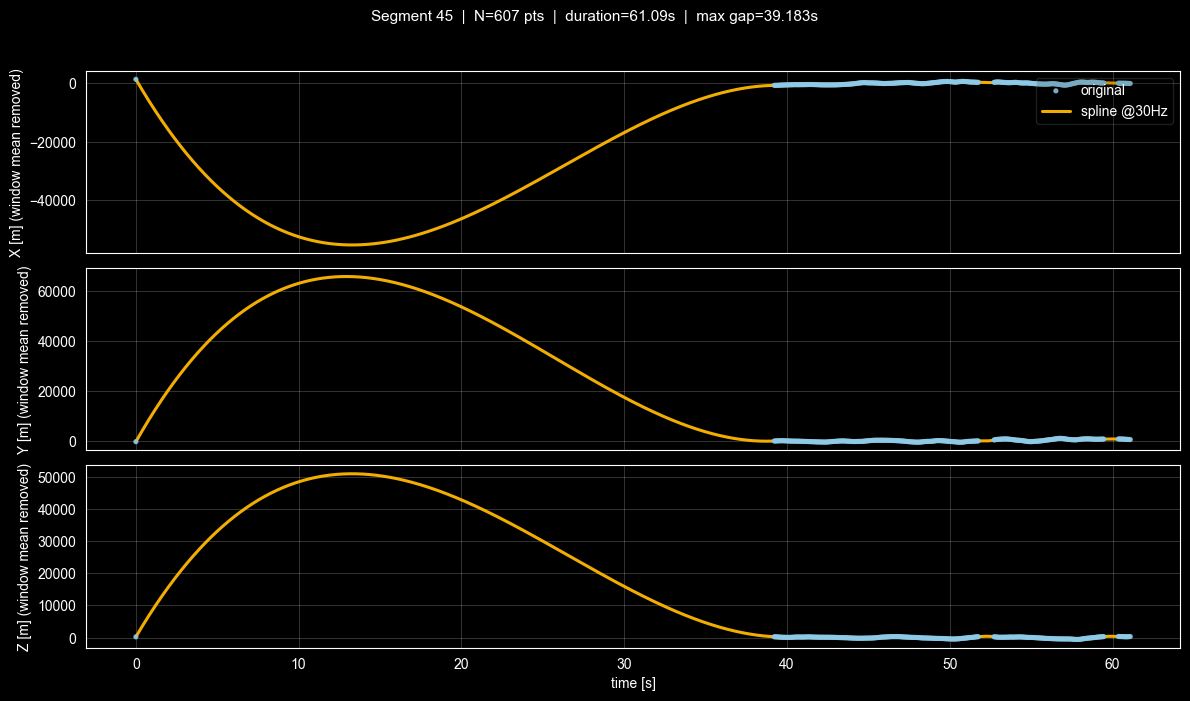

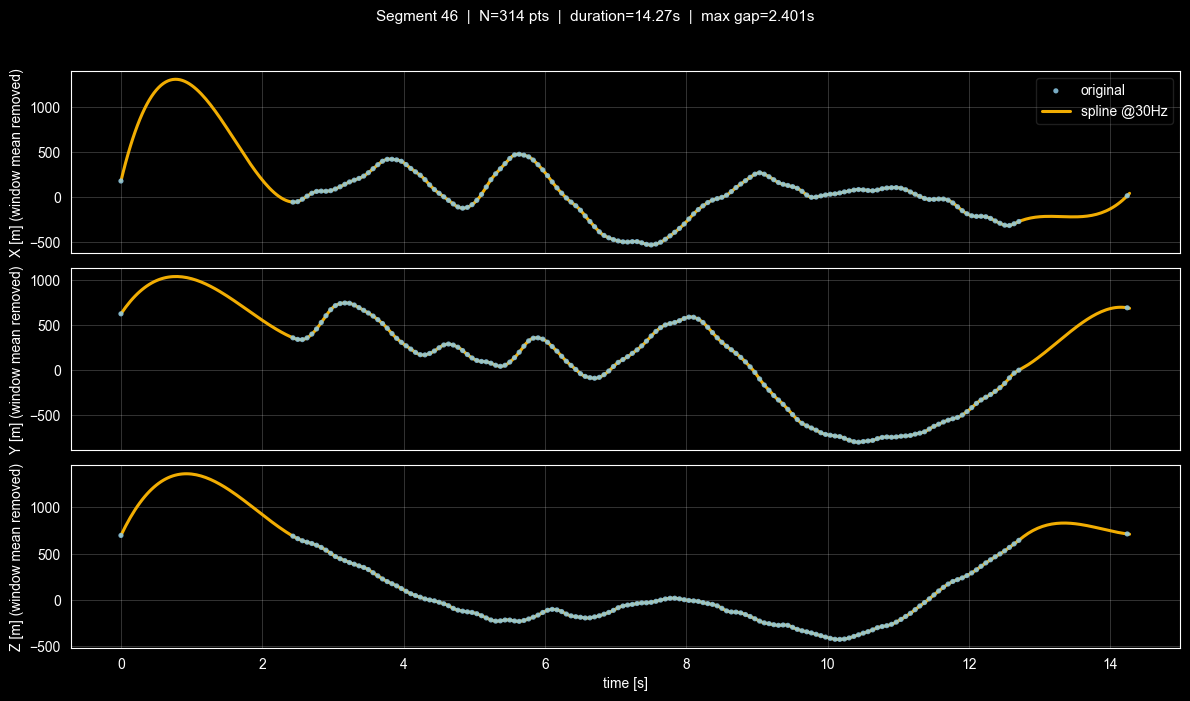

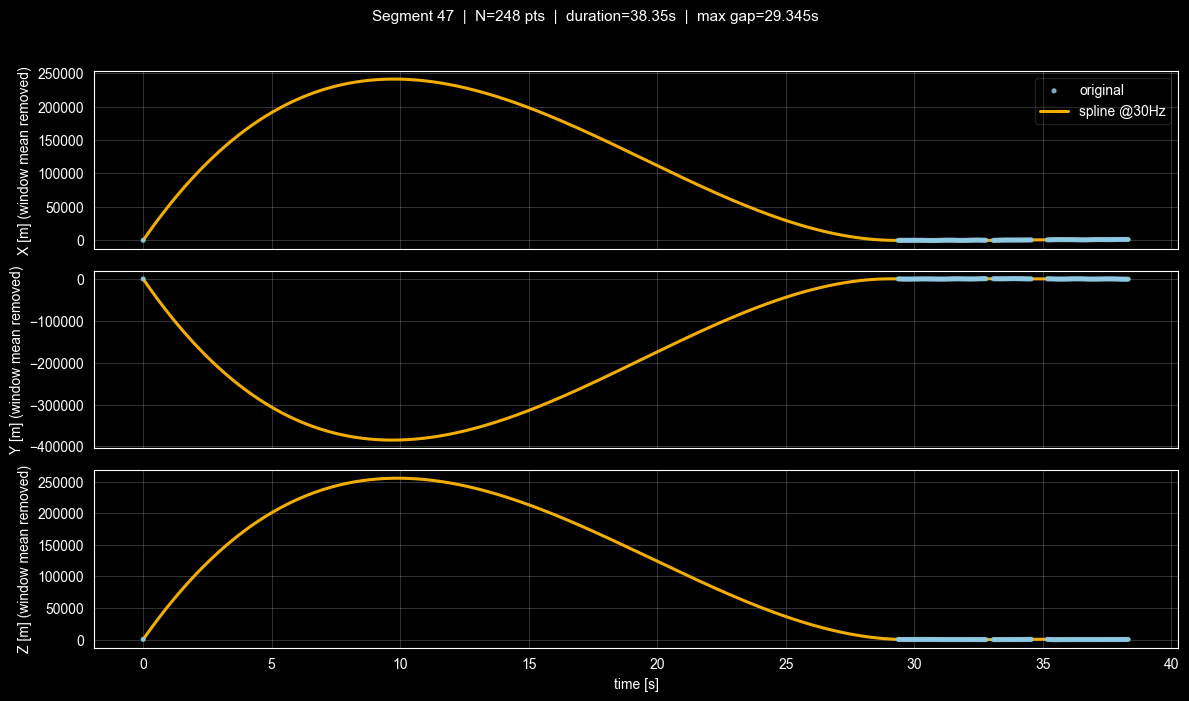

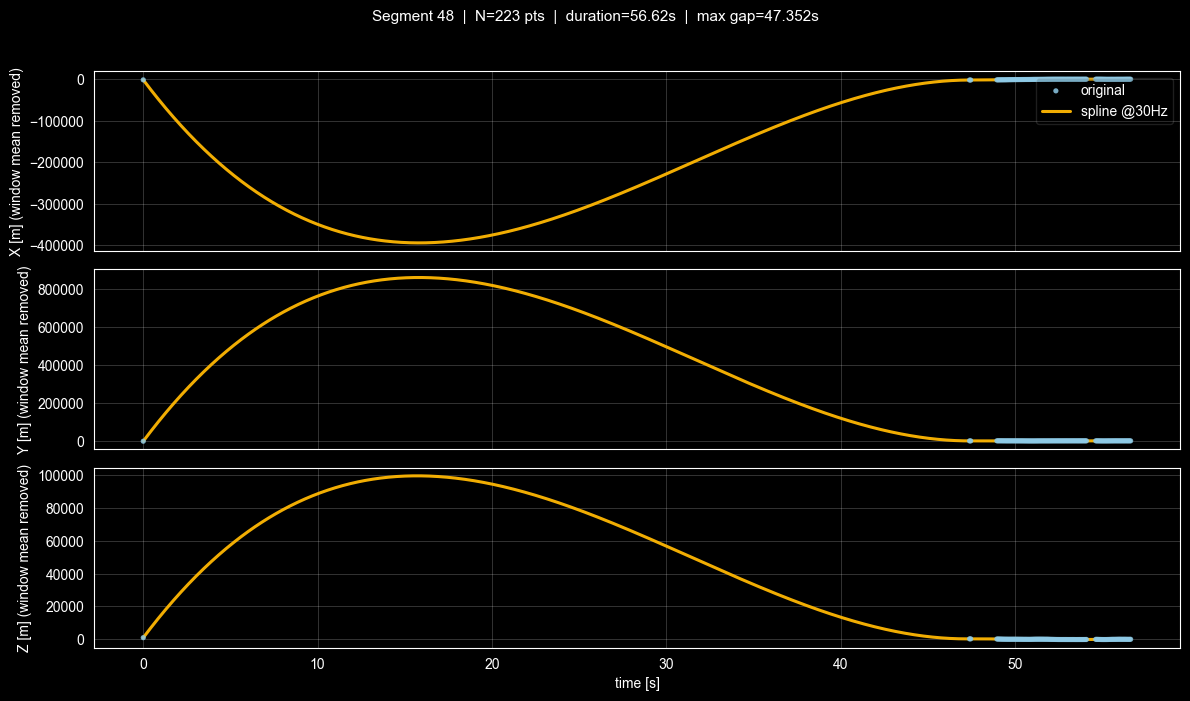

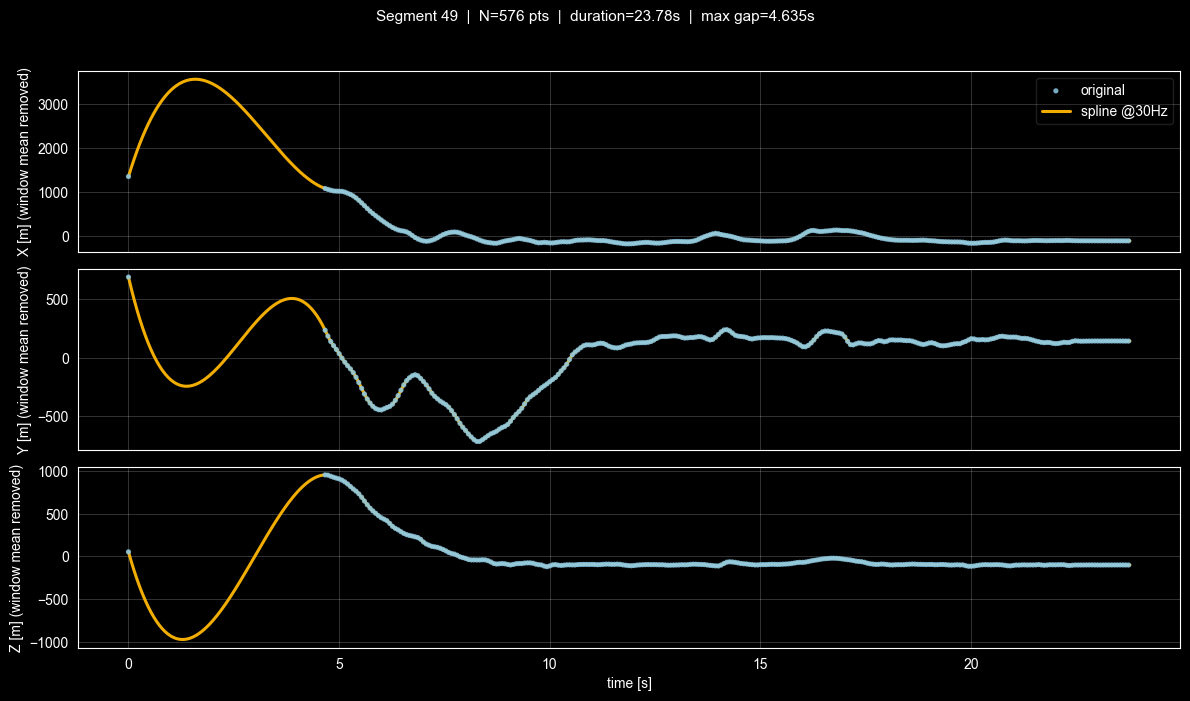

In [118]:
#For plotting cubic spline
from matplotlib.backends.backend_pdf import PdfPages

def plot_original_vs_interp_range(all_times, all_coords,
                                  start, end, fps=30,
                                  mode="window",          # "global" or "window"
                                  chan_names=("X","Y","Z"),
                                  units="m",
                                  decimate=1,
                                  save_pdf=None,
                                  dark=True):

    if dark:
        plt.style.use("dark_background")
    orig_c   = "#8ecae6"   #Set colours
    spline_c = "#ffb703"
    grid_kw  = dict(alpha=0.20, linewidth=0.7)

    idxs = list(range(start, end))
    if not idxs:
        print("Nothing to plot (empty range)"); return

    pdf = PdfPages(save_pdf) if save_pdf else None
    for i in idxs:
        t_raw   = all_times[i]
        xyz_raw = all_coords[i]
        if len(t_raw) < 3:
            print(f"skip seg {i}: too few points ({len(t_raw)})")
            continue

        #Spline to uniform timebase
        t_lin, xyz_spline = resample_segment(t_raw, xyz_raw, fps=fps)

        # Shift times to segment start
        t0 = float(t_raw.min())
        tr = t_raw - t0
        tl = t_lin - t0

        #Remove per-window mean
        if mode == "window":
            mu = xyz_raw.mean(axis=0, keepdims=True)
            xyz_raw_plot    = xyz_raw - mu
            xyz_spline_plot = xyz_spline - mu
            ylab_suffix = " (window mean removed)"
        else:
            xyz_raw_plot    = xyz_raw
            xyz_spline_plot = xyz_spline
            ylab_suffix = ""

        #Figure
        fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
        for c, ax in enumerate(axes):
            # ORIGINAL (scatter) — brighter points
            ax.scatter(tr[::decimate], xyz_raw_plot[::decimate, c],
                       s=14, color=orig_c, alpha=0.85, edgecolor="none",
                       label="original" if c == 0 else None, zorder=3)


            ax.plot(tl, xyz_spline_plot[:, c],
                    color=spline_c, linewidth=2.2, alpha=0.95,
                    label=f"spline @{fps}Hz" if c == 0 else None, zorder=2)

            ax.set_ylabel(f"{chan_names[c]} [{units}]{ylab_suffix}")
            ax.grid(**grid_kw)

        axes[-1].set_xlabel("time [s]")
        axes[0].legend(loc="upper right", framealpha=0.15)
        fig.suptitle(
            f"Segment {i}  |  N={len(t_raw)} pts  |  duration={tr.max():.2f}s  |  max gap={np.diff(np.sort(t_raw)).max():.3f}s",
            y=0.995, fontsize=11
        )
        plt.tight_layout(rect=[0, 0, 1, 0.97])

        if pdf:
            pdf.savefig(fig); plt.close(fig)
        else:
            plt.show()

    if pdf:
        pdf.close()
        print(f"Saved {len(idxs)} pages to: {save_pdf}")


#Show segments within range
plot_original_vs_interp_range(
    all_times, all_coords,
    start=1, end=50, fps=30,
    mode="window", decimate=2,
    chan_names=("X","Y","Z"),
    save_pdf=None,
    dark=True
)


In [61]:
print(train_data.shape)
print(val_data.shape)

(163705, 60, 3)
(43474, 60, 3)


In [62]:
import torch


if torch.cuda.is_available():
  device = torch.device('cuda:0')
  print('Running on the GPU')
else:
  device = torch.device('cpu')
  print('Running on the CPU')

Running on the CPU


In [63]:
#Define model arcitecture
import torch.nn as nn

#Shape of data = (Batch size, 60, 3)

#latent grid = (min_fmaps, 15) ≈ latent_elems
class Encoder(nn.Module):
    def     __init__(self, in_channels=3, filters=16, min_fmaps=16): #minimum amount of feature maps each layer
        super().__init__()
        self.net = nn.Sequential(
            #Spatial dimension of output = ((Input - Filter + 2(Padding))/Stride))+1
            #Input = 60
            #Filter = 3
            #Stride = 1
            #Padding = 1
            #Output = (((60 - 3) + 2)/1) + 1
            #=60
            #(Batch size, in_channels, 60) → (Batch size, filters, 60)

            #Number of parameters = ((3 * 3) + 1) * 16
            nn.Conv1d(in_channels, filters, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(filters), nn.ReLU(),

            #(Batch size, filters, 60) → (Batch size, filters, 60)
            nn.Conv1d(filters, filters, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(filters), nn.ReLU(),

            #(Batch size, filters, 60) → (Batch size, 2*filters, 30)
            nn.Conv1d(filters, 2*filters, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm1d(2*filters), nn.ReLU(),
            #60 → 30

            #(Batch size, 2*filters, 30) → (Batch size, 2*filters, 30)
            nn.Conv1d(2*filters, 2*filters, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(2*filters), nn.ReLU(),

            #(Batch size, 2*base_channels, 30) → (Batch size, min_fmaps, 15)
            nn.Conv1d(2*filters, min_fmaps, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm1d(min_fmaps), nn.ReLU(),
            #30 → 15
        )

    def forward(self, x):  #x shape = (Batch size, 3, 60)
        return self.net(x) #(Batch size, min_fmaps, 15)


class Decoder(nn.Module):
    def __init__(self, in_channels=3, filters=16, min_fmaps=16):
        super().__init__()
        self.net = nn.Sequential(
            #(Batch size, min_fmaps, 15) → (Batch size, 2*filters, 30)
            nn.ConvTranspose1d(min_fmaps, 2*filters,
                               kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm1d(2*filters), nn.ReLU(),

            #(Batch size, 2*filters, 30) → (Batch size, 2*filters, 30)
            nn.Conv1d(2*filters, 2*filters, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(2*filters), nn.ReLU(),

            #(Batch size, 2*filters, 30) → (Batch size, filters, 60)
            nn.ConvTranspose1d(2*filters, filters,
                               kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm1d(filters), nn.ReLU(),

            #(Batch size, filters, 60) → (Batch size, filters, 60)
            nn.Conv1d(filters, filters, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(filters), nn.ReLU(),

            #(Batch size, filters, 60) → (Batch size, in_channels, 60)
            nn.Conv1d(filters, in_channels, kernel_size=3, stride=1, padding=1),
        )

    def forward(self, x):
        return self.net(x)


class Autoencoder(nn.Module):
    def __init__(self, in_channels=3, base_channels=16, latent_elems=256):
        #latent_elems = min_fmaps * T_bottleneck
        super().__init__()
        t_bottleneck = 15
        #T-bottleneck is the time length at the narrowest point of encoder
        #from 60 → 30 → 15
        min_fmaps = max(1, round(latent_elems / t_bottleneck))
        self.encoder = Encoder(in_channels, base_channels, min_fmaps)
        self.decoder = Decoder(in_channels, base_channels, min_fmaps)

    def forward(self, x):
        return self.decoder(self.encoder(x))




In [120]:
import torch
import numpy as np
from torch.utils.data import TensorDataset, DataLoader

#Load autoencoder, weights, and embeddings from saved file

device = "cpu"
latent_elems = 256
ckpt_path = r"D:\Project\autoencoder_train.pth"

#Recreate the model
ae = Autoencoder(in_channels=3, base_channels=16, latent_elems=latent_elems).to(device)

#Load weights
state = torch.load(ckpt_path, map_location=device)
ae.load_state_dict(state)
ae.eval()

encoder = ae.encoder.eval()  #Extract encoder


fixed_len = 60

#Combine train and val data
segments = np.concatenate([train_data, val_data], axis=0)  #shape (N, 60, 3)

#Convert to torch tensor and permute to (N, 3, 60)
segment_tensor = torch.tensor(segments.transpose(0, 2, 1), dtype=torch.float32)

loader = DataLoader(TensorDataset(segment_tensor), batch_size=64, shuffle=False)

#Encode to embeddings
embeddings = []
with torch.no_grad():
    for (x,) in loader:
        x = x.to(device)
        z = encoder(x)
        embeddings.append(z.cpu())

embeddings = torch.cat(embeddings, dim=0).numpy()
print("Embeddings shape:", embeddings.shape)



Embeddings shape: (85144, 17, 15)


In [125]:
#Use K-means clustering for a specific k value
Z = embeddings

X = Z.reshape(Z.shape[0], -1)

import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

use_cosine = True

if use_cosine:
    X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    metric = "cosine"
else:
    X = StandardScaler().fit_transform(X)
    metric = "euclidean"

km = KMeans(n_clusters=3, n_init=10, random_state=0)
labels = km.fit_predict(X)

sil = silhouette_score(X, labels, metric=metric)
print("features shape:", X.shape)
print(f"global silhouette = {sil:.3f}")




features shape: (85144, 255)
global silhouette = 0.835


k sweep in 8.4s  (N=85144, subset=5000)
k : inertia/N | silhouette | CH | DB (↓)
 2 : 1.2118e-01 |  0.7584 |  4584.6 |  0.909
 3 : 1.0019e-01 |  0.7648 |  3317.9 |  1.255
 4 : 8.1673e-02 |  0.7383 |  3011.5 |  1.159
 5 : 7.1426e-02 |  0.7434 |  2726.5 |  1.294
 6 : 6.5636e-02 |  0.7378 |  2508.7 |  1.316
 7 : 6.3378e-02 |  0.6978 |  2166.9 |  1.271


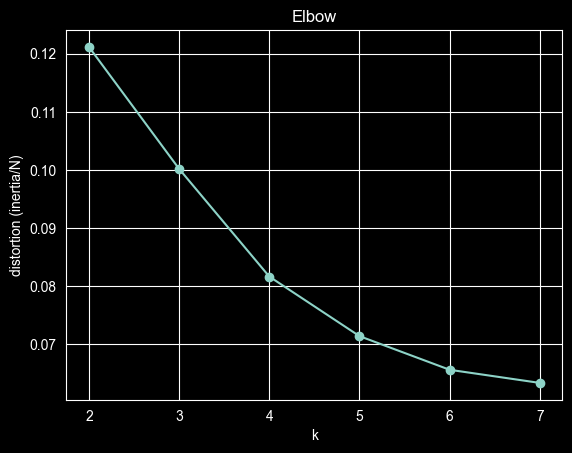

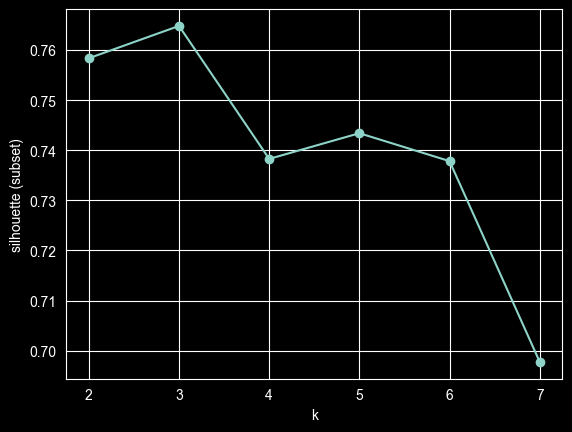

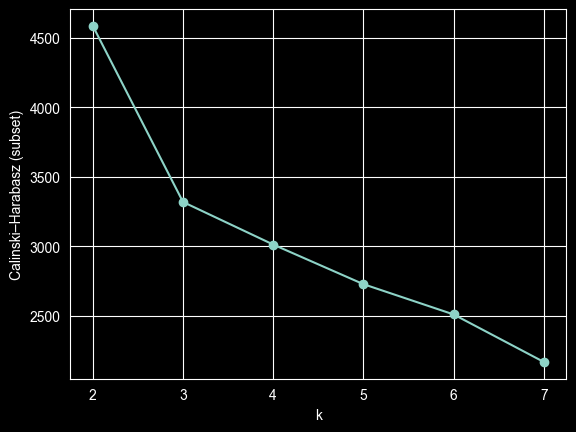

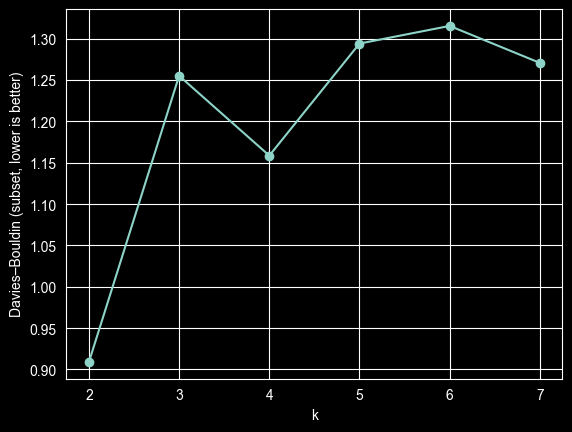

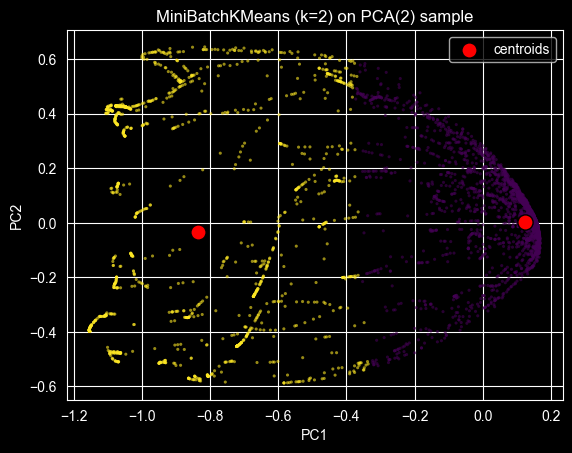

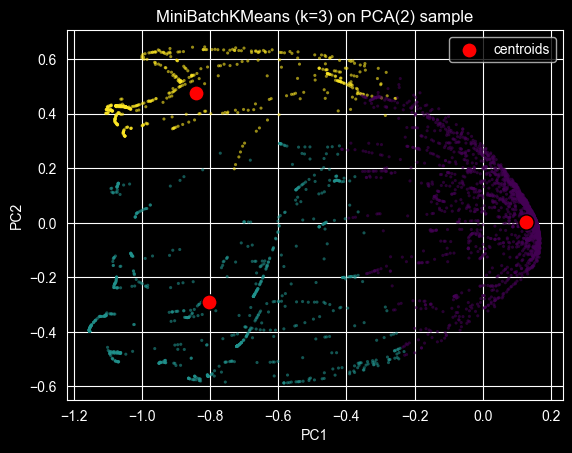

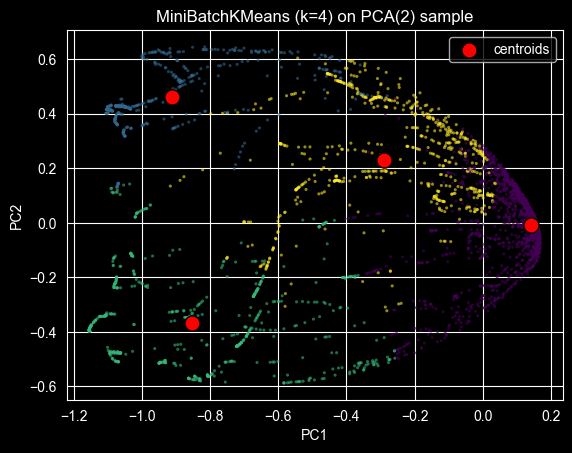

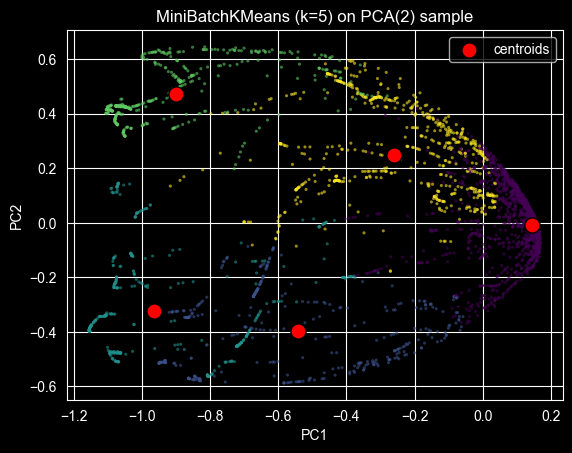

In [124]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA

#List of parameters
#Added as this code previously took an extensive amount of time to run
K_LIST   = range(2, 8)
SUBSET   = 5000
VIS      = 10000
BATCH    = 2048
N_INIT   = 5

#Features and normalisarion
Z = embeddings
X = Z.reshape(Z.shape[0], -1).astype(np.float32)
X /= (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9)

N = X.shape[0]
rng = np.random.RandomState(42)
sub_idx = rng.choice(N, size=min(SUBSET, N), replace=False)
X_sub = X[sub_idx]

t0 = time.time()
inertias, sils, chs, dbs = [], [], [], []

for k in K_LIST:
    km = MiniBatchKMeans(
        n_clusters=k, batch_size=BATCH, n_init=N_INIT,
        reassignment_ratio=0.01, random_state=42
    )
    km.fit(X)
    inertias.append(km.inertia_)

    #Labels on subset, silhouette with sampling
    lab_sub = km.predict(X_sub)
    sil = silhouette_score(X_sub, lab_sub, metric="euclidean",
                           sample_size=min(5000, len(X_sub)), random_state=42)
    sils.append(sil)
    chs.append(calinski_harabasz_score(X_sub, lab_sub))
    dbs.append(davies_bouldin_score(X_sub, lab_sub))

t1 = time.time()
print(f"k sweep in {t1 - t0:.1f}s  (N={N}, subset={len(X_sub)})")

print("k : inertia/N | silhouette | CH | DB (↓)")
for k, I, s, ch, db in zip(K_LIST, inertias, sils, chs, dbs):
    print(f"{k:>2} : {I/N:.4e} | {s: .4f} | {ch: .1f} | {db: .3f}")

#Elbow/silhouette plots
plt.figure(); plt.plot(K_LIST, [I/N for I in inertias], "o-"); plt.grid(True)
plt.xlabel("k"); plt.ylabel("distortion (inertia/N)"); plt.title("Elbow")

plt.figure(); plt.plot(K_LIST, sils, "o-"); plt.grid(True)
plt.xlabel("k"); plt.ylabel("silhouette (subset)")

plt.figure(); plt.plot(K_LIST, chs, "o-"); plt.grid(True)
plt.xlabel("k"); plt.ylabel("Calinski–Harabasz (subset)")

plt.figure(); plt.plot(K_LIST, dbs, "o-"); plt.grid(True)
plt.xlabel("k"); plt.ylabel("Davies–Bouldin (subset, lower is better)")
plt.show()

#2D visualisation on a sample
vis_idx = rng.choice(N, size=min(VIS, N), replace=False)
X_vis = X[vis_idx]
pca = PCA(n_components=2, svd_solver="randomized", random_state=42)
X_vis_2d = pca.fit_transform(X_vis)

for k in range(2, 6):
    km = MiniBatchKMeans(n_clusters=k, batch_size=BATCH, n_init=N_INIT, random_state=42).fit(X)
    y = km.predict(X_vis)
    centers_2d = pca.transform(km.cluster_centers_)
    plt.figure()
    plt.scatter(X_vis_2d[:, 0], X_vis_2d[:, 1], c=y, cmap="viridis", s=5, alpha=0.6, edgecolor="none")
    plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c="red", s=120, edgecolor="k", label="centroids")
    plt.title(f"MiniBatchKMeans (k={k}) on PCA(2) sample")
    plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(); plt.grid(True)
    plt.show()


In [110]:
#Find the worst and best validation windows by reconstruction error
# Also give summary on the error per channel for those two groups
def topk_windows_by_metric(mse_abs_all, k=5, chan_names=("X","Y","Z")):

    mean_mse = mse_abs_all.mean(axis=1)
    worst_idx = np.argsort(-mean_mse)[:k]
    best_idx  = np.argsort(mean_mse)[:k]
    print(f"\nWorst {k} windows by mean MSE (orig): {worst_idx.tolist()}")
    print(f"Best  {k} windows by mean MSE (orig): {best_idx.tolist()}")
    for name, ids in [("worst", worst_idx), ("best", best_idx)]:
        ch_mse = mse_abs_all[ids].mean(axis=0)
        print(f"  {name} group mean MSE per channel: " +
              ", ".join(f"{c}={v:.3e}" for c,v in zip(chan_names, ch_mse)))

def threshold_summary(mse_norm_all, corr_all, chan_names=("X","Y","Z")):

    #Simple 'pass-rate'-style metrics
    #e.g What fraction of windows meet an MSE threshold
    th_mse = [0.01, 0.05, 0.10]
    for t in th_mse:
        frac = (mse_norm_all.mean(axis=1) < t).mean()  #Fraction of windows
        print(f"Fraction of windows with mean MSE(norm) < {t:.2f}: {frac:.2%}")

    for c, cname in enumerate(chan_names):
        frac = (np.nan_to_num(corr_all[:,c]) >= 0.5).mean()
        print(f"Fraction of windows with r≥0.5 in {cname}: {frac:.2%}")


In [111]:
import numpy as np, torch


def _safe_corr(x, y):

    #Computes a per-channel Pearson correlation between an original window x and its reconstruction y
    x = x - x.mean(axis=0, keepdims=True)
    y = y - y.mean(axis=0, keepdims=True)

    xs = x.std(axis=0)
    ys = y.std(axis=0)
    denom = xs * ys + 1e-12

    r = (x * y).mean(axis=0) / denom
    r[(xs < 1e-12) | (ys < 1e-12)] = np.nan
    return r

@torch.no_grad()
def eval_recon_summary_full(model, device,
                            val_data, val_data_init, data_mean, data_std,
                            batch_size=1024, chan_names=("X","Y","Z")):

    #Computes metrics over the entire validation set
    #Prints mean ± std, median, and p95

    ds = TensorDataset(torch.tensor(val_data.transpose(0,2,1), dtype=torch.float32))  # (N,3,60)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=False)

    mse_norm_all, mse_abs_all, mae_abs_all, nrmse_all, corr_all = [], [], [], [], []

    offset = 0  # <-- number of windows consumed so far

    for (x,) in dl:
        x = x.to(device)
        y = model(x).cpu()

        # back to (B,60,3)
        Xn = x.permute(0,2,1).cpu().numpy()
        Yn = y.permute(0,2,1).cpu().numpy()

        B = Xn.shape[0]
        idxs = np.arange(offset, offset + B)     # <-- correct alignment
        offset += B

        Xo = val_data_init[idxs]                                # (B,60,3)
        Yo = Yn * data_std[None,None,:] + data_mean[None,None,:]

        # metrics per window, per channel
        mse_n = ((Yn - Xn)**2).mean(axis=1)                     # (B,3)
        mse_a = ((Yo - Xo)**2).mean(axis=1)                     # (B,3)
        mae_a =  np.abs(Yo - Xo).mean(axis=1)                   # (B,3)
        rng   = (Xo.max(axis=1) - Xo.min(axis=1)) + 1e-8        # (B,3)
        nrmse = np.sqrt(mse_a) / rng                            # (B,3)

        r = np.vstack([_safe_corr(Xo[i], Yo[i]) for i in range(B)])  # (B,3)

        mse_norm_all.append(mse_n); mse_abs_all.append(mse_a)
        mae_abs_all.append(mae_a);  nrmse_all.append(nrmse)
        corr_all.append(r)

    mse_norm_all = np.vstack(mse_norm_all)
    mse_abs_all  = np.vstack(mse_abs_all)
    mae_abs_all  = np.vstack(mae_abs_all)
    nrmse_all    = np.vstack(nrmse_all)
    corr_all     = np.vstack(corr_all)

    def stats(name, arr):
        mean = np.nanmean(arr, axis=0); std = np.nanstd(arr, axis=0)
        med  = np.nanmedian(arr, axis=0)
        p95  = np.nanpercentile(arr, 95, axis=0)
        txt  = f"{name:>12}  " + "  ".join([f"{c}: {m:.4e} ± {s:.4e} | med={md:.4e} | p95={p:.4e}"
                                            for c,m,s,md,p in zip(chan_names, mean, std, med, p95)])
        print(txt)

    print("\n=== Reconstruction metrics over the full validation set ===")
    stats("MSE (norm)", mse_norm_all)
    stats("MSE (orig)", mse_abs_all)
    stats("MAE (orig)", mae_abs_all)
    stats("NRMSE",      nrmse_all)

    mean_corr = np.nanmean(corr_all, axis=0); std_corr = np.nanstd(corr_all, axis=0)
    med_corr  = np.nanmedian(corr_all, axis=0)
    p95_corr  = np.nanpercentile(corr_all, 95, axis=0)
    frac_pos  = np.mean(np.nan_to_num(corr_all) >= 0.5, axis=0)
    print("   Corr (r)  " + "  ".join([f"{c}: mean={m:.3f}±{s:.3f} | med={md:.3f} | p95={p:.3f} | frac(r≥0.5)={fp:.2f}"
                                      for c,m,s,md,p,fp in zip(chan_names, mean_corr, std_corr, med_corr, p95_corr, frac_pos)]))

    # at the very end of eval_recon_summary_full:
    return mse_norm_all, mse_abs_all, nrmse_all, corr_all




In [70]:
def set_seed(seed=0):
    import random, numpy as np, torch
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False



initial length of training and validation 70974 14170
After transposing data 70974 14170
length of loaders 555 111
epoch  1/150  train MSE=0.477625  val MSE=0.153393
epoch  2/150  train MSE=0.189726  val MSE=0.100666
epoch  3/150  train MSE=0.104771  val MSE=0.094447
epoch  4/150  train MSE=0.080434  val MSE=0.060502
epoch  5/150  train MSE=0.066747  val MSE=0.080965
epoch  6/150  train MSE=0.060656  val MSE=0.040194
epoch  7/150  train MSE=0.053951  val MSE=0.068871
epoch  8/150  train MSE=0.051269  val MSE=0.035219
epoch  9/150  train MSE=0.046361  val MSE=0.038249
epoch 10/150  train MSE=0.043792  val MSE=0.041097
epoch 11/150  train MSE=0.042964  val MSE=0.028104
epoch 12/150  train MSE=0.038828  val MSE=0.039567
epoch 13/150  train MSE=0.039233  val MSE=0.050656
epoch 14/150  train MSE=0.034449  val MSE=0.033026
epoch 15/150  train MSE=0.034214  val MSE=0.030854
epoch 16/150  train MSE=0.032321  val MSE=0.031906
epoch 17/150  train MSE=0.028600  val MSE=0.028277
epoch 18/150  trai

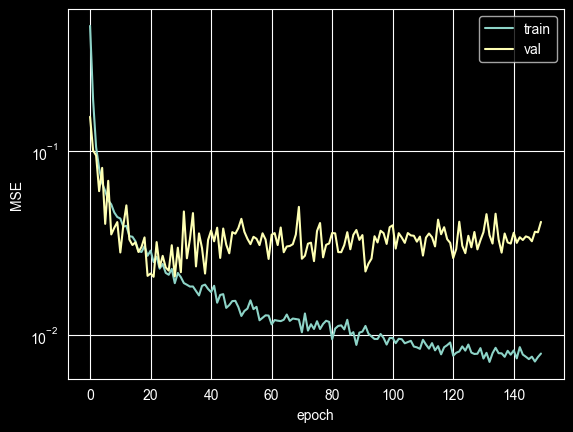


=== Reconstruction metrics over the full validation set ===
  MSE (norm)  X: 1.1397e-02 ± 7.5000e-02 | med=4.2046e-06 | p95=2.8567e-02  Y: 1.0721e-01 ± 8.9310e-01 | med=1.9991e-07 | p95=4.5054e-02  Z: 4.9926e-03 ± 2.2818e-02 | med=1.3910e-06 | p95=2.7396e-02
  MSE (orig)  X: 1.9378e+13 ± 1.2751e+14 | med=7.1486e+09 | p95=4.8569e+13  Y: 5.2106e+14 ± 4.3403e+15 | med=9.7154e+08 | p95=2.1896e+14  Z: 6.0947e+12 ± 2.7853e+13 | med=1.6980e+09 | p95=3.3442e+13
  MAE (orig)  X: 1.1031e+06 ± 3.4671e+06 | med=4.3653e+04 | p95=6.6584e+06  Y: 4.3019e+06 ± 2.2206e+07 | med=2.3100e+04 | p95=1.4331e+07  Z: 7.4956e+05 ± 2.1023e+06 | med=4.0827e+04 | p95=5.5298e+06
       NRMSE  X: 1.5361e+10 ± 3.4789e+11 | med=1.7117e+02 | p95=1.3774e+05  Y: 3.5457e+09 ± 1.0147e+11 | med=7.7180e+01 | p95=2.1270e+04  Z: 5.1272e+10 ± 4.5131e+11 | med=1.3358e+02 | p95=4.5950e+04
   Corr (r)  X: mean=-0.002±0.318 | med=-0.019 | p95=0.451 | frac(r≥0.5)=0.03  Y: mean=0.006±0.114 | med=0.000 | p95=0.216 | frac(r≥0.5)=0.00  

(array([[4.0404193e-06, 2.0481387e-07, 1.3593610e-06],
        [4.0324699e-06, 2.0590159e-07, 1.3369968e-06],
        [4.1372523e-06, 2.0453562e-07, 1.3485339e-06],
        ...,
        [4.1726134e-06, 1.8753344e-07, 1.3170336e-06],
        [4.1624839e-06, 1.8648399e-07, 1.3138014e-06],
        [4.1589160e-06, 1.9036052e-07, 1.3182648e-06]],
       shape=(14170, 3), dtype=float32),
 array([[6.86939082e+09, 9.95387554e+08, 1.65932345e+09],
        [6.85587190e+09, 1.00067208e+09, 1.63202420e+09],
        [7.03401650e+09, 9.94034195e+08, 1.64610721e+09],
        ...,
        [7.09413824e+09, 9.11405112e+08, 1.60765545e+09],
        [7.07692148e+09, 9.06302944e+08, 1.60371037e+09],
        [7.07085163e+09, 9.25143992e+08, 1.60915866e+09]], shape=(14170, 3)),
 array([[ 24.39834629,  89.30733873,  58.44412264],
        [ 63.65353745, 733.69422493, 573.67262903],
        [ 29.99417297, 166.3302317 , 123.46853752],
        ...,
        [638.79517024, 100.10414534, 270.40799786],
        [399.

In [119]:
from torch.utils.data import TensorDataset


import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F

def training_init(num_epochs, train_data, val_data, batch_size=128, lr=1e-4):
    print("initial length of training and validation", len(train_data), len(val_data))


    train_t = torch.tensor(train_data.transpose(0,2,1), dtype=torch.float32)
    val_t   = torch.tensor(val_data.transpose(0,2,1),   dtype=torch.float32)
    print("After transposing data", len(train_t), len(val_t))

    train_loader = DataLoader(TensorDataset(train_t), batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(TensorDataset(val_t),   batch_size=batch_size, shuffle=False)
    print("length of loaders", len(train_loader), len(val_loader))

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


    model = Autoencoder(in_channels=3, base_channels=16, latent_elems=256).to(device)

    optim = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.MSELoss(reduction='mean')

    train_hist, val_hist = [], []

    for epoch in range(1, num_epochs+1):
        #Training
        model.train()
        sse_train, n_train = 0.0, 0

        for b, (x,) in enumerate(train_loader, 1):
            x = x.to(device)
            y = model(x)

            loss_mean = criterion(y, x)
            optim.zero_grad(); loss_mean.backward(); optim.step()

            elems = x.numel()
            sse_train += loss_mean.item() * elems
            n_train   += elems

        train_mse_epoch = sse_train / n_train
        train_hist.append(train_mse_epoch)

        #Validation
        model.eval()
        sse_val, n_val = 0.0, 0
        with torch.no_grad():
            for (x,) in val_loader:
                x = x.to(device)
                y = model(x)
                loss_mean = F.mse_loss(y, x, reduction='mean')
                elems = x.numel()
                sse_val += loss_mean.item() * elems
                n_val   += elems

        val_mse_epoch = sse_val / n_val
        val_hist.append(val_mse_epoch)

        print(f"epoch {epoch:2d}/{num_epochs}  train MSE={train_mse_epoch:.6f}  val MSE={val_mse_epoch:.6f}")

    return model, train_hist, val_hist



set_seed()
model, train_mse, val_mse = training_init(150, train_data, val_data)

#Save model
save_path = r"D:\Project\autoencoder_train.pth"
torch.save(model.state_dict(), save_path)

#Plot mse
import matplotlib.pyplot as plt
plt.plot(train_mse, label="train")
plt.plot(val_mse,   label="val")
plt.yscale("log")
plt.legend(); plt.xlabel("epoch"); plt.ylabel("MSE")
plt.show()


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = Autoencoder(in_channels=3, base_channels=16, latent_elems=256)
model.load_state_dict(torch.load(save_path, map_location=device))
model.to(device).eval()

eval_recon_summary_full(model, device,
                        val_data, val_data_init, data_mean, data_std,
                        batch_size=1024, chan_names=("X","Y","Z"))


In [44]:
def evaluate_reconstruction(model, data, device="cpu", batch_size=128):
    """
    Computes average reconstruction error over the dataset.
    """
    model.eval()
    data_tensor = torch.tensor(data.transpose(0,2,1), dtype=torch.float32)  # (N, 3, T)
    loader = DataLoader(TensorDataset(data_tensor), batch_size=batch_size, shuffle=False)

    total_loss, n_total = 0.0, 0
    with torch.no_grad():
        for (x,) in loader:
            x = x.to(device)
            y = model(x)
            loss = F.mse_loss(y, x, reduction='sum')  # total squared error
            total_loss += loss.item()
            n_total += x.numel()

    avg_mse = total_loss / n_total
    return avg_mse





In [43]:
# import torch
# import torch.nn.functional as F
# from torch.utils.data import DataLoader, TensorDataset
# import matplotlib.pyplot as plt
# import numpy as np
#
# def training_init_detailed(num_epochs, train_data, val_data, batch_size=128, lr=1e-3,
#                            ma_window=200, record_val_batches=False):
#
#     train_t = torch.tensor(train_data.transpose(0,2,1), dtype=torch.float32)
#     val_t   = torch.tensor(val_data.transpose(0,2,1),   dtype=torch.float32)
#
#     train_loader = DataLoader(TensorDataset(train_t), batch_size=batch_size, shuffle=True)
#     val_loader   = DataLoader(TensorDataset(val_t),   batch_size=batch_size, shuffle=False)
#
#     device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#     model  = Autoencoder(in_channels=3, base_channels=32, latent_elems=256).to(device)
#     optim  = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
#
#
#     train_epoch_mse, val_epoch_mse = [], []
#     train_batch_mse, val_batch_mse = [], []
#     batches_per_epoch = []  # for plotting epoch separators
#
#     for epoch in range(1, num_epochs+1):
#         #training
#         model.train()
#         sse_train, n_train = 0.0, 0
#         b_count = 0
#
#         for (x,) in train_loader:
#             x = x.to(device)
#             y = model(x)
#             loss_mean = F.mse_loss(y, x, reduction='mean')
#
#             optim.zero_grad()
#             loss_mean.backward()
#             optim.step()
#
#             # record per-batch
#             batch_mse = loss_mean.item()
#             train_batch_mse.append(batch_mse)
#             b_count += 1
#
#             # accumulate for exact epoch MSE
#             elems = x.numel()              # B*C*T
#             sse_train += batch_mse * elems # mean * count = SSE
#             n_train   += elems
#
#         batches_per_epoch.append(b_count)
#         train_epoch_mse.append(sse_train / n_train)
#
#         #validation
#         model.eval()
#         sse_val, n_val = 0.0, 0
#         with torch.no_grad():
#             for (x,) in val_loader:
#                 x = x.to(device)
#                 y = model(x)
#                 loss_mean = F.mse_loss(y, x, reduction='mean')
#
#                 if record_val_batches:
#                     val_batch_mse.append(loss_mean.item())
#
#                 elems = x.numel()
#                 sse_val += loss_mean.item() * elems
#                 n_val   += elems
#
#         val_epoch_mse.append(sse_val / n_val)
#         print(f"epoch {epoch:2d}/{num_epochs}  "
#               f"train MSE={train_epoch_mse[-1]:.6f}  val MSE={val_epoch_mse[-1]:.6f}")
#
#     return model, train_epoch_mse, val_epoch_mse, train_batch_mse, val_batch_mse, batches_per_epoch
#
# def plot_mse_detailed(train_epoch, val_epoch, train_batch, batches_per_epoch, ma_window=200):
#     """Batch curve (thin), moving average, and epoch means (thick), with epoch separators."""
#     tb = np.array(train_batch, dtype=float)
#     te = np.array(train_epoch, dtype=float)
#     ve = np.array(val_epoch, dtype=float)
#
#
#     xb = np.arange(1, len(tb)+1)
#
#
#     if ma_window and ma_window > 1 and len(tb) > ma_window:
#         w = np.ones(ma_window) / ma_window
#         tb_ma = np.convolve(tb, w, mode='valid')
#         xb_ma = np.arange(ma_window, len(tb)+1)
#     else:
#         tb_ma, xb_ma = None, None
#
#
#     cum = np.cumsum([0] + list(batches_per_epoch))
#     centers = 0.5 * (cum[:-1] + cum[1:])
#
#     plt.figure(figsize=(10,6))
#     plt.yscale('log')
#
#
#     plt.plot(xb, tb, alpha=0.25, linewidth=1, label='train batch')
#
#
#     if tb_ma is not None:
#         plt.plot(xb_ma, tb_ma, linewidth=2, label=f'train batch (mean average of  {ma_window} batches)')
#
#
#     plt.plot(centers, te, linewidth=3, marker='o', label='train epoch')
#     plt.plot(centers, ve, linewidth=3, marker='o', label='val epoch')
#
#
#     for xline in cum[1:-1]:
#         plt.axvline(xline, color='gray', alpha=0.15, linewidth=1)
#
#     plt.xlabel('batch (vertical line = epoch boundary)')
#     plt.ylabel('MSE')
#     plt.legend()
#     plt.tight_layout()
#     plt.show()
#
#
#
# model, train_ep, val_ep, train_bt, val_bt, bpe = training_init_detailed(
#     num_epochs=20, train_data=train_data, val_data=val_data,
#     batch_size=128, lr=1e-3, ma_window=200, record_val_batches=False
# )
#
#
# plot_mse_detailed(train_ep, val_ep, train_bt, bpe, ma_window=200)
